## 03 — Single-shot FEL spectral characterization

GOTTHARD monitors the **X-ray spectrum of each shot**: centre, width, intensity and
resolved spectral structure. Molecular photoelectron and resonant Auger–Meitner XAS
belongs to the magnetic-bottle eTOF measurement. Detector intensity here is not molecular XAS.

Run sections **1–7 in order from a fresh kernel** for a bounded scan preview. No raw
processing, good-product generation or automatic export occurs. The original 63 cells,
their scientific statements and saved outputs follow in optional section 8. Their old
compilation-status text is archival; Stage 1D documents exact historical source replay.
No full analysis was executed for this refocus. The proposal PDF was not found locally;
the purpose above follows the clarified experimental brief.

## 1. Setup, data selection and provenance

Use notebook 01 to establish run-dependent frame/native-GMD matching and notebook 02
for background and detailed calibration review. This notebook reads the stored mapping
without rolls, shifts or another background subtraction. Product axes are
`vls[section, padded shot, pixel]`, mapped GMD `[section, padded shot, channel]`;
only rows `[0,n_shots[section])` count as recorded shots (half-open).

Historical optics/anchor and peak parameters below are **provisional examples**, not
settings validated for the next target. Sources: baseline `e3dfa92bf5669a882d67dc5e772e915e4638d645`
and updated main `f940ee05ddc9fbbd2b0faa95cc25085608792323`, inspected read-only at
`/home/mmanresa/glycine26_main_review`. Exact functions/adaptations are recorded in
`historical_sources_03_fel.json`; all archival cell indices are zero-based including Markdown.
Dependencies: project requirements plus existing optional `pandas` used by the reused QC helper.

**Sampling:** `FEL_SHOTS_PER_SECTION=128` takes uniformly spaced recorded rows
(including endpoints, or all rows if fewer) from **every stored section** by default.
`FEL_SECTIONS=None` keeps repeated acquisitions separate. This is a deterministic
analysis sample, not full-run statistics. Increase the sample size here; memory and
peak-finding time scale with sections × sampled shots × pixels. Display limits
`FEL_SPECTRA_PER_CLASS` and `FEL_QUALITY_SPECTRA_PER_GROUP` affect individual lineouts
only: means, SDs, fits, histograms and fractions always use the whole analysis sample.

Plotting and simple masks/binning are inline below. Helpers retain read-only HDF5
loading/identity checks, peak finding/classification, centre/calibration assignment,
RMS/FWHM metrics, numerical response fits, summary tables and explicit CSV export.
Historical cells and their saved outputs are preserved; main diagnostic outputs
are cleared so rerunning displays results for the visible settings.

In [114]:
import os
import sys
from pathlib import Path
PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard').resolve()
sys.dont_write_bytecode = True
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache' / 'matplotlib')
os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
if not (PROJECT_ROOT / 'AGENTS.md').is_file():
    raise RuntimeError(f'Project root unavailable: {PROJECT_ROOT}')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import asdict
from historical import config as path_config
from historical import fel_spectral_diagnostics as fel

from importlib import reload
# Refresh before constructing FEL, including when reusing an open Jupyter kernel.
fel = reload(fel)
print('Using helper:', Path(fel.__file__).resolve())

Using helper: /home/mmanresa/FLASH_Gotthard/historical/fel_spectral_diagnostics.py


In [115]:
# Beamtime controls. Run-dependent calibration/peak parameters follow in FEL.
FEL_RUN = 58794
FEL_SHOTS_PER_SECTION = 1000
FEL_SECTIONS = None  # all stored scan sections; or an explicit tuple of section indices
FEL_SPECTRA_PER_CLASS = 1  # displayed individual examples; does not change statistics
FEL_QUALITY_SPECTRA_PER_GROUP = 1
FEL_EXAMPLE_SECTION = 4
FEL_GMD_EDGES = np.arange(0., 22., 2.)  # half-open [lo, hi), final edge excluded
FEL_FIXED_ENERGIES_EV = (275., 277., 282.)
FEL_FIXED_ENERGY_ATOL_EV = 1e-6
# Explicit optional product: choose None when no matching good product is required.
FEL_GOOD_H5 = PROJECT_ROOT / f'products/static_xas_good/run{FEL_RUN}_good_static_xas.h5'
FEL_EXPORT_CSV = None
HISTORICAL_SECTIONS = set()  # opt in with {'A'}, {'B'}, etc.; see section 8
if not HISTORICAL_SECTIONS <= set('ABCDEFG'):
    raise ValueError('Historical sections must be chosen from A–G')
for limit in (FEL_SPECTRA_PER_CLASS, FEL_QUALITY_SPECTRA_PER_GROUP):
    if not isinstance(limit, int) or limit < 0:
        raise ValueError('Individual-spectrum display limits must be nonnegative integers')

In [116]:
# Scientific definitions retained unchanged; provisional calibration for this run.
FEL = fel.FELConfig(
    input_h5=path_config.XAS_STATIC_DIR/f'run{FEL_RUN}_static_xas.h5',
    good_h5=FEL_GOOD_H5,
    shots_per_section=FEL_SHOTS_PER_SECTION, sections=FEL_SECTIONS,   # None: sample every stored section
    gmd_dataset='ml/gmd_hall_channels', gmd_channel=0,
    center_method='com', center_half_window=5,  # peak, smooth_peak, gaussian_logfit also available
    historical_peak_threshold=1000., historical_gmd_min=None, historical_gmd_max=10.,
    preview_snr_threshold=5., classification_snr=5., # diagnostic choices, never universal filters
    baseline_quantile=.15, sg_window=9, sg_poly=2,
    double_peak_kwargs=dict(min_distance_px=3, max_distance_px=17,
        min_prom_sigma=2.5, min_height_sigma=2., min_rel_peak_height=.35,
        min_second_ratio=.05, min_bridge_drop=.015, min_split_sigma=.75),
    geometry=dict(source_to_grating_m=.85, grating_to_screen_m=.5429,
        incident_angle_deg=86.78, groove_density_lines_per_mm=1200.,
        diffraction_order=1, magnification=3., pixel_pitch_m=50e-6, axis_sign=1),
    anchor=dict(pixel=524., energy_eV=284.2), inverse_range_eV=(260.,290.),
)

In [117]:
print('Resolved ordinary input:', Path(FEL.input_h5).resolve())
print('Optional good input:', Path(FEL.good_h5).resolve() if FEL.good_h5 is not None else None)
print('All scientific settings:', asdict(FEL))
print('Software versions:', fel.software_versions())
print('GMD bins:', FEL_GMD_EDGES, 'example section:', FEL_EXAMPLE_SECTION)
print('Fixed nominal energies (eV):', FEL_FIXED_ENERGIES_EV, 'matching atol (eV):', FEL_FIXED_ENERGY_ATOL_EV)

Resolved ordinary input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5
Optional good input: /home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58794_good_static_xas.h5
All scientific settings: {'input_h5': PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), 'good_h5': PosixPath('/home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58794_good_static_xas.h5'), 'shots_per_section': 1000, 'sections': None, 'gmd_dataset': 'ml/gmd_hall_channels', 'gmd_channel': 0, 'center_method': 'com', 'center_half_window': 5, 'historical_peak_threshold': 1000.0, 'historical_gmd_min': None, 'historical_gmd_max': 10.0, 'classification_snr': 5.0, 'preview_snr_threshold': 5.0, 'baseline_quantile': 0.15, 'sg_window': 9, 'sg_poly': 2, 'double_peak_kwargs': {'min_distance_px': 3, 'max_distance_px': 17, 'min_prom_sigma': 2.5, 'min_height_sigma': 2.0, 'min_rel_peak_height': 0.35, 'min_second_ratio': 0.05, 'min_bridg

In [118]:
# Bounded detector reads only: <=FEL_SHOTS_PER_SECTION recorded rows/section, no selection cuts.
# Missing/unreadable explicit good inputs raise; choose None to run without that product.
fel_preview = fel.load_preview(FEL)
fel_table = fel_preview['table']
print('Schema:', fel_preview['schema'])
print('Acquisition/background/energy provenance:', fel_preview['attrs'])
print('Run identities:', np.unique(fel_table['run_id']))
print('Section / recorded / sampled:', fel_preview['sections'])
print('Sample spectra:', fel_preview['spectra'].shape, 'bytes:', fel_preview['spectra'].nbytes)
print('Stored GOTTHARD indices:', np.unique(fel_table['vls_bunch_index']),
      'native GMD indices:', np.unique(fel_table['gmd_bunch_index']))
print('Finite spectrum/GMD/QC counts:', np.sum(fel_table['finite_spectrum']),
      np.sum(np.isfinite(fel_table['gmd'])), np.sum(fel_table['qc_ok']))
print('Good input contains accepted shots only:', fel_preview['input_good'])

Schema: {'vls': ((31, 102720, 200), 'float64'), 'n_shots': ((31,), 'int64'), 'vls_pixels': ((200,), 'int64'), 'ml/gmd_hall_channels': ((31, 102720, 8), 'float32'), 'noise/vls_bg_sigma_global': ((200,), 'float64')}
Acquisition/background/energy provenance: {'bg_bunch_range': array([ 50, 100]), 'config': np.int64(2), 'config_path': 'analysis/configs/xas_static/5mmol_gly_03June_night.py', 'first_section_state': 'open', 'gmd_bunch_start': np.int64(0), 'gmd_signal_bunch_range': array([ 0, 30]), 'gmd_source': 'ml/gmd_hall_channels[..., 0]', 'gmd_tunnel_index_path': '/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy tunnel/index', 'gmd_tunnel_present': np.True_, 'gmd_tunnel_source': 'ml/gmd_tunnel_channels[..., 0]', 'gmd_tunnel_value_path': '/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy tunnel/value', 'ml_schema_version': '1.0', 'mode': 'xas_static', 'n_sections_detected': np.int64(31), 'n_sections_used': np.int64(31), 'raw_dir': '/home/kaiyu/glycine26/11022188/raw/hdf/online-

## 2. Scan overview and representative spectra

Uniformly spaced recorded rows within each section form a **deterministic preview**,
not a random full-run estimate. Each plotted shot has equal weight; section medians/SDs
refer to this sample. Repeated nominal settings retain separate section identities.
The scan map shows unnormalised mean lineouts, preserving amplitude changes. Example
spectra and low/high-GMD quartile means reuse the historical lineout/tail diagnostics
without their XAS cuts. Variability shading is shot **SD**, not uncertainty on the mean.
The original overview applies no detector/GMD division, intercept correction, new
measured-background subtraction or spectral resampling. Upstream off-pulse/closed-shutter subtraction remains
as documented in the archive below; a fitted intercept is not measured background.

The additional fixed-energy panels match `FEL_FIXED_ENERGIES_EV` against the
stored `nominal_eV` labels with the displayed absolute tolerance (no nearest-energy
fallback). Each repeated acquisition keeps its own section, fit and panel. These
are **intensity-response diagnostics**; notebook 01 used similar correlations
principally to assess pulse alignment. Pearson r and unweighted linear fits with
intercept use the same finite GMD/intensity pairs, without QC or peak cuts. Slopes
are signed pixel-sum a.u. per native GMD a.u.; intercepts are pixel-sum a.u.
Constant GMD or fewer than two pairs gives unavailable fits/r; constant intensity
has unavailable r. The ratio panel uses positive GMD only and shows individual
shot ratios, not a ratio of sums or an OD observable. A fitted intercept alone can
produce a ratio trend, so a trend does not by itself establish detector nonlinearity.

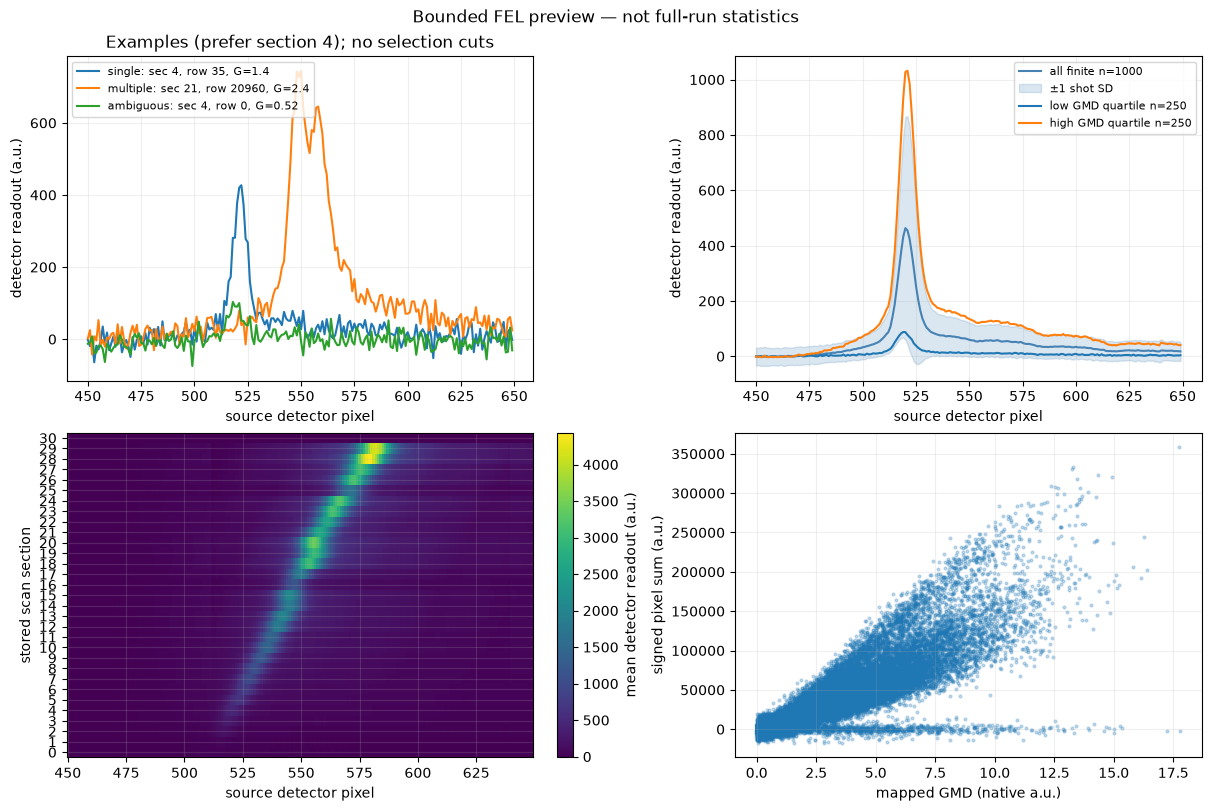

In [119]:
# Scan overview and displayed examples
section = FEL_EXAMPLE_SECTION
(fel_table, fel_spectra, x) = (fel_preview['table'], fel_preview['spectra'], fel_preview['pixels'])
m = fel_table['section_index'] == section
if not m.any():
    raise ValueError('Example section was not sampled')
(fig, ax) = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for label in ('single', 'multiple', 'ambiguous'):
    ii = np.flatnonzero(m & (fel_table['classification'] == label))[:FEL_SPECTRA_PER_CLASS]
    if label == 'multiple' and (not len(ii)):
        ii = np.flatnonzero(fel_table['classification'] == label)[:FEL_SPECTRA_PER_CLASS]
    for i in ii:
        ax[0, 0].plot(x, fel_spectra[i], label=f"{label}: sec {fel_table['section_index'][i]}, row {fel_table['source_shot_index'][i]}, G={fel_table['gmd'][i]:.2g}")
if not np.any(fel_table['classification'] == 'multiple'):
    ax[0, 0].text(0.98, 0.04, 'No resolved multiple peak in this sample',
        ha='right', transform=ax[0, 0].transAxes, fontsize=8)
finite = m & fel_table['finite_spectrum']
if finite.any():
    (mean, sd) = (fel_spectra[finite].mean(0), fel_spectra[finite].std(0))
    ax[0, 1].plot(x, mean, color='steelblue', label=f'all finite n={finite.sum()}')
    ax[0, 1].fill_between(x, mean - sd, mean + sd, color='steelblue', alpha=0.2, label='±1 shot SD')
ids = np.flatnonzero(finite & np.isfinite(fel_table['gmd']))
if len(ids):
    ids = ids[np.argsort(fel_table['gmd'][ids])]
    n = max(1, len(ids) // 4)
    for (group, label) in ((ids[:n], 'low GMD quartile'), (ids[-n:], 'high GMD quartile')):
        ax[0, 1].plot(x, fel_spectra[group].mean(0), label=f'{label} n={len(group)}')

# Scan overview and displayed examples (continued)
secs = np.unique(fel_table['section_index'])
means = [fel_spectra[(fel_table['section_index'] == s) & fel_table['finite_spectrum']].mean(0) if np.any((fel_table['section_index'] == s) & fel_table['finite_spectrum']) else np.full(len(x),
    np.nan) for s in secs]
im = ax[1, 0].imshow(means, origin='lower', aspect='auto', interpolation='nearest',
    extent=(x[0] - 0.5, x[-1] + 0.5, -0.5, len(secs) - 0.5))
ax[1, 0].set_yticks(range(len(secs)), secs)
fig.colorbar(im, ax=ax[1, 0], label='mean detector readout (a.u.)')
ax[1, 1].scatter(fel_table['gmd'], fel_table['intensity_signed_sum'], s=4, alpha=0.25)
for a in ax[0]:
    a.set(xlabel='source detector pixel', ylabel='detector readout (a.u.)')
    a.legend(fontsize=8)
ax[0, 0].set_title(f'Examples (prefer section {section}); no selection cuts')
ax[1, 0].set(xlabel='source detector pixel', ylabel='stored scan section')
ax[1, 1].set(xlabel='mapped GMD (native a.u.)', ylabel='signed pixel sum (a.u.)')
fig.suptitle('Bounded FEL preview — not full-run statistics')
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

In [120]:
# Exact stored-energy matching; retain repeated acquisitions as separate panels.
atol = FEL_FIXED_ENERGY_ATOL_EV
energies = np.asarray(FEL_FIXED_ENERGIES_EV, dtype=float)
if energies.ndim != 1 or not len(energies) or (not np.all(np.isfinite(energies))):
    raise ValueError('Choose a nonempty finite nominal-energy vector')
if not np.isfinite(atol) or atol < 0:
    raise ValueError('Energy matching tolerance must be finite and nonnegative')
t = fel_table
fel_fixed_sections = []
for energy in energies:
    matches = []
    for section in np.unique(t['section_index']):
        values = np.unique(t['nominal_eV'][t['section_index'] == section])
        if len(values) != 1:
            raise ValueError(f'Inconsistent nominal labels in section {section}')
        if np.isclose(values[0], energy, atol=atol, rtol=0):
            matches.append((int(section), float(values[0])))
    if not matches:
        raise ValueError(f'No sampled stored section matches {energy:g} eV (atol={atol:g})')
    for match in matches:
        if match in fel_fixed_sections:
            raise ValueError('Requested energies select the same section more than once')
        fel_fixed_sections.append(match)
print('Selected stored (section, nominal eV):', fel_fixed_sections)

Selected stored (section, nominal eV): [(19, 275.0), (20, 275.0), (14, 277.0), (15, 277.0), (4, 282.0)]


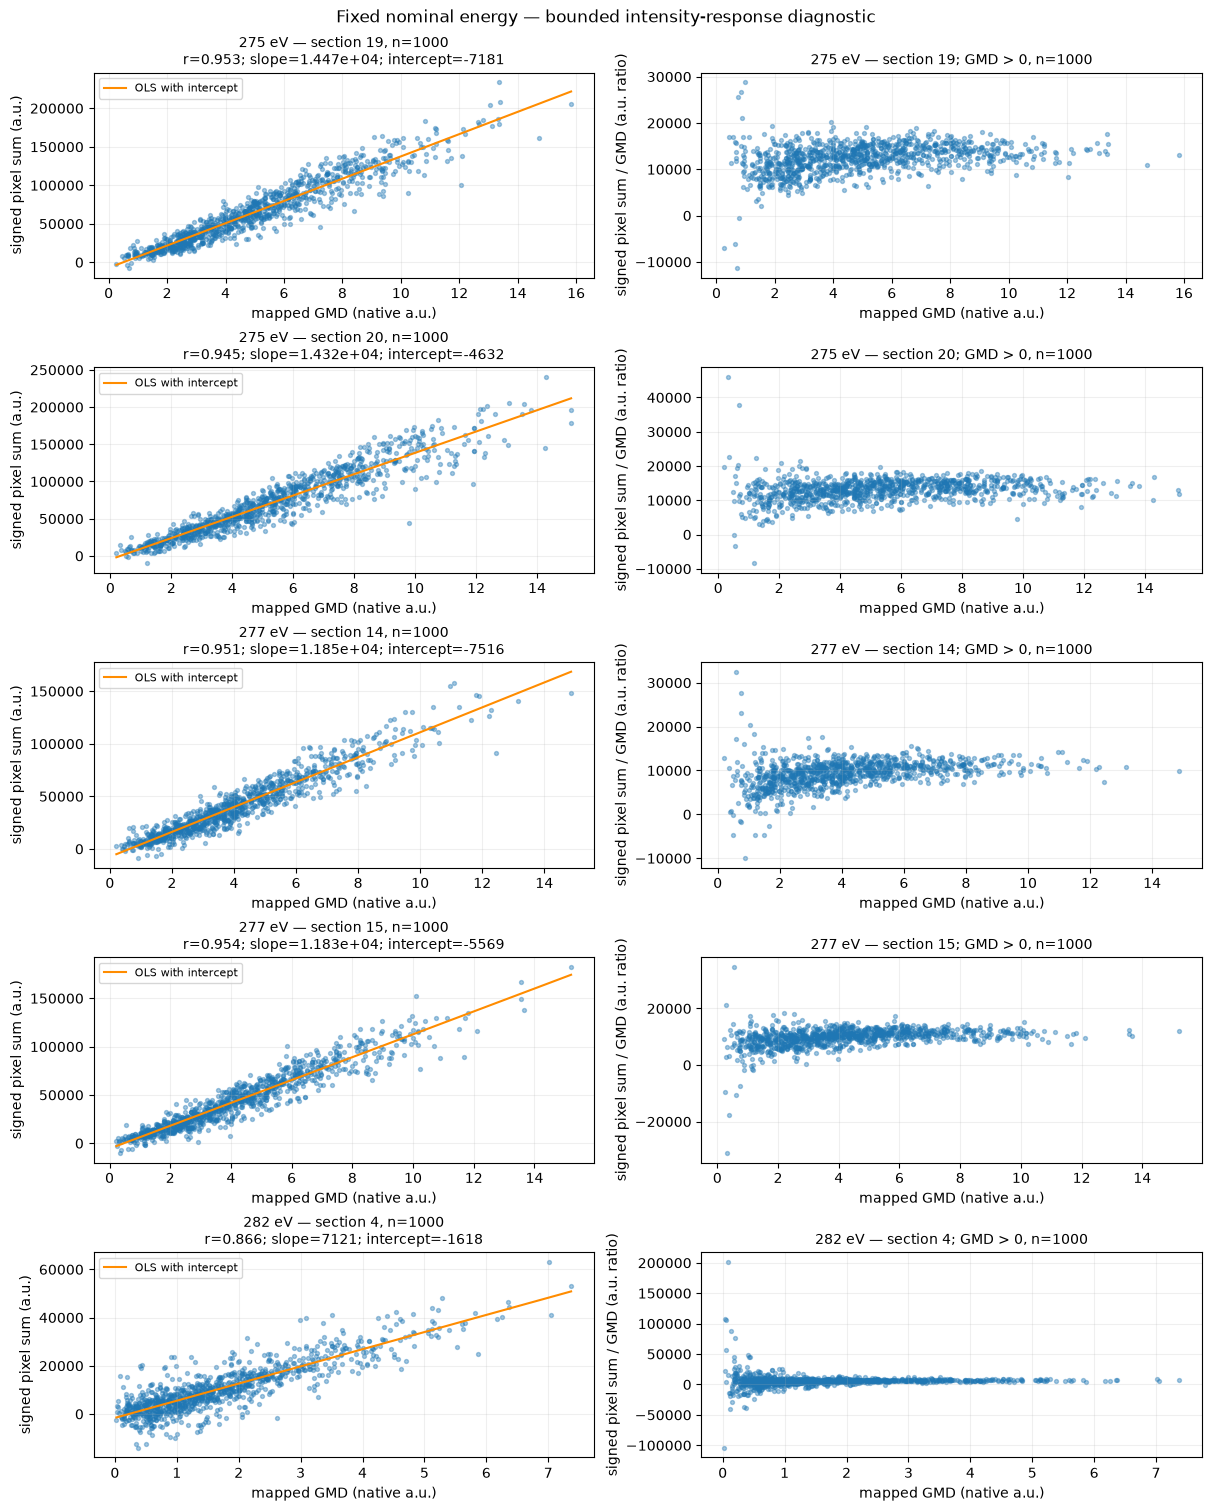

In [121]:
# Fixed-energy intensity response
(fig, ax) = plt.subplots(len(fel_fixed_sections), 2, figsize=(12, 3 * len(fel_fixed_sections)),
    squeeze=False, constrained_layout=True)
for ((section, energy), axes) in zip(fel_fixed_sections, ax):
    m = (fel_table['section_index'] == section) & np.isfinite(fel_table['gmd']) & np.isfinite(fel_table['intensity_signed_sum'])
    (x, y) = (fel_table['gmd'][m], fel_table['intensity_signed_sum'][m])
    stats = fel.intensity_response_stats(x, y)
    axes[0].scatter(x, y, s=8, alpha=0.4)
    if np.isfinite(stats['slope']):
        xx = np.array([x.min(), x.max()])
        axes[0].plot(xx, stats['slope'] * xx + stats['intercept'],
            color='darkorange', label='OLS with intercept')
        axes[0].legend(fontsize=8)
    axes[0].set_title(f"{energy:g} eV — section {section}, n={stats['n']}\nr={stats['pearson_r']:.3g}; slope={stats['slope']:.4g}; intercept={stats['intercept']:.4g}",
        fontsize=10)
    positive = x > 0
    axes[1].scatter(x[positive], y[positive] / x[positive], s=8, alpha=0.4)
    axes[1].set_title(f'{energy:g} eV — section {section}; GMD > 0, n={positive.sum()}', fontsize=10)
    axes[0].set(xlabel='mapped GMD (native a.u.)', ylabel='signed pixel sum (a.u.)')
    axes[1].set(xlabel='mapped GMD (native a.u.)', ylabel='signed pixel sum / GMD (a.u. ratio)')
fig.suptitle('Fixed nominal energy — bounded intensity-response diagnostic')
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

## 3. Calibration and peak-centre analysis

Compare the unchanged historical local strongest-peak estimator (default positive-weight
COM within ±5 pixels), raw argmax and diagnostic full-ROI centroid. Local centres can
follow one lobe of a multi-peak spectrum; full-ROI centroids respond to all lobes and residual
background. Alternatives `peak`, `smooth_peak` and `gaussian_logfit` use the historical helpers;
the latter two explicitly smooth/fit internally. Changing `center_method` reruns only the bounded preview.

Geometry uses the historical 524 px → 284.2 eV anchor, magnification 3 and inverse map
260–290 eV/10,000 grid points. Out-of-domain centres yield NaN, never clamped endpoints.
The optional good product supplies an empirical polynomial trained on accepted local
baseline-clipped QC COM centres versus stored section energies. The comparison panel
evaluates **both at the same QC centre**, avoiding an estimator-population mismatch.
Both assignments are retained; the approximately 3.1 eV discrepancy previously observed
is not removed or evidence that either is physically superior. Nominal energies are
setpoint-derived labels, not independent absolute-energy standards. Empirical extrapolation
is flagged against the range of stored section centres. No counts/eV density or absolute
bandwidth calibration is claimed; widths below stay in pixels. Notebook 02 owns validation.

The added two-spectrum diagnostic uses the highest and lowest finite stored-noise
peak SNR within `FEL_EXAMPLE_SECTION` in the existing sample. “Strong” and “weak”
are relative sample extremes, not new selection thresholds. It marks the historical
local peak COM (explicitly `com`, with the configured half-window), the existing
full-ROI centroid and the actual ROI midpoint. Shading shows the latter's weights:
`max(stored spectrum − per-shot quantile baseline, 0)`, with no smoothing.
For pixels 450–649 the midpoint is **549.5**, close to 550. At low signal, residual
pedestal and positive clipped noise spread weights over the ROI; roughly uniform
weights pull the centroid toward this midpoint. This is not evidence of a peak at
550 or a calibration failure. Asymmetric backgrounds/noise can pull it elsewhere.
The local COM instead follows a narrow window about the strongest sample, which
can itself be noise when the signal is weak. Neither estimator is changed.

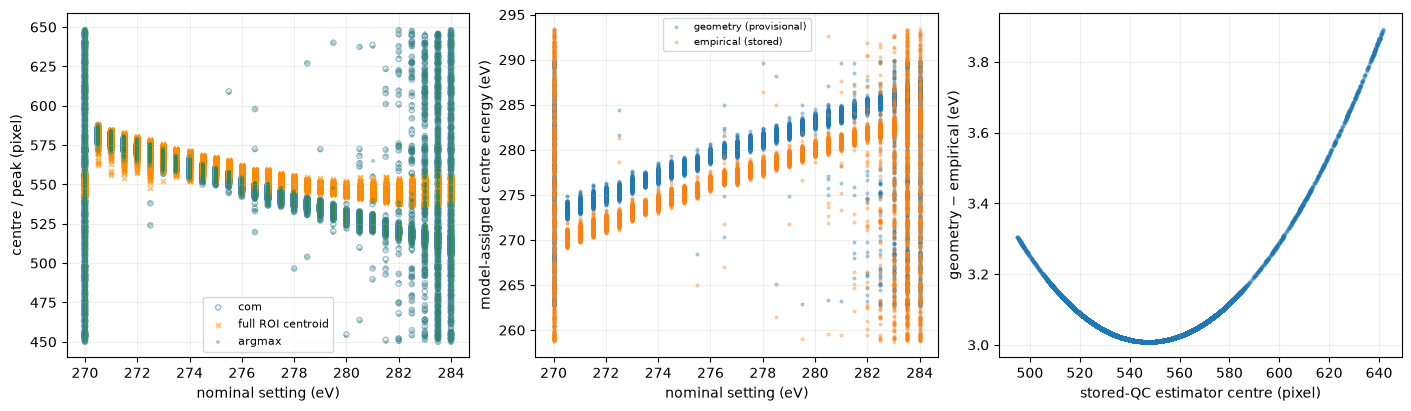

In [122]:
# Calibration comparison
(fig, ax) = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
ax[0].scatter(fel_table['nominal_eV'], fel_table['center_pixel'], s=14,
    alpha=0.55, color='steelblue', marker='o', facecolors='none', label=fel_preview['config'].center_method)
ax[0].scatter(fel_table['nominal_eV'], fel_table['roi_centroid_pixel'],
    s=12, alpha=0.5, color='darkorange', marker='x', label='full ROI centroid')
ax[0].scatter(fel_table['nominal_eV'], fel_table['peak_pixel'], s=10,
    alpha=0.4, color='seagreen', marker='+', label='argmax')
ax[0].legend(fontsize=8)
for (key, label) in (('geometry_qc_center_eV', 'geometry (provisional)'),
    ('empirical_qc_center_eV', 'empirical (stored)')):
    if np.isfinite(fel_table[key]).any():
        ax[1].scatter(fel_table['nominal_eV'], fel_table[key], s=4, alpha=0.3, label=label)
ax[1].legend(fontsize=7)
ax[2].scatter(fel_table['qc_center_pixel'], fel_table['geometry_qc_center_eV'] - fel_table['empirical_qc_center_eV'],
    s=4, alpha=0.3)
if fel_preview['good'] is None:
    ax[2].text(0.5, 0.5, 'Optional empirical calibration unavailable',
        ha='center', transform=ax[2].transAxes, fontsize=9)
ax[0].set(xlabel='nominal setting (eV)', ylabel='centre / peak (pixel)')
ax[1].set(xlabel='nominal setting (eV)', ylabel='model-assigned centre energy (eV)')
ax[2].set(xlabel='stored-QC estimator centre (pixel)', ylabel='geometry − empirical (eV)')
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

In [123]:
print('Unavailable geometrical centres:', np.sum(~np.isfinite(fel_table['geometry_eV'])))
print('Empirical extrapolation flags:', np.sum(fel_table['empirical_extrapolated']))
fel_difference = fel_table['geometry_qc_center_eV'] - fel_table['empirical_qc_center_eV']
if np.isfinite(fel_difference).any():
    print('Sample geometry−empirical [16,50,84] percentiles (eV):',
          np.nanpercentile(fel_difference, [16,50,84]))
else:
    print('No empirical comparison available; pixel/geometry workflow remains independent.')

Unavailable geometrical centres: 511
Empirical extrapolation flags: 2609
Sample geometry−empirical [16,50,84] percentiles (eV): [3.01142139 3.03739243 3.10057258]


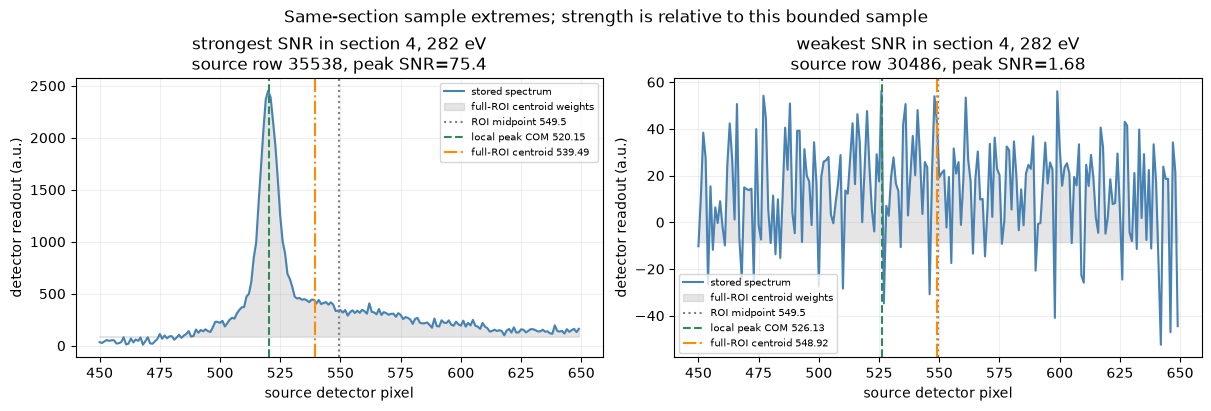

In [124]:
# Strong/weak same-section centroid examples
section = FEL_EXAMPLE_SECTION
(fel_table, fel_spectra, x, cfg) = (fel_preview['table'], fel_preview['spectra'],
    fel_preview['pixels'], fel_preview['config'])
ids = np.flatnonzero((fel_table['section_index'] == section) & fel_table['finite_spectrum'] & np.isfinite(fel_table['peak_snr']))
if len(ids) < 2:
    raise ValueError('Centroid diagnostic needs at least two finite spectra/SNRs in the example section')
ids = ids[np.argsort(fel_table['peak_snr'][ids], kind='stable')]
(fig, ax) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
midpoint = (x[0] + x[-1]) / 2
for (a, i, label) in zip(ax, (ids[-1], ids[0]), ('strongest SNR', 'weakest SNR')):
    y = fel_spectra[i]
    local = fel.sxa.estimate_center_pixels(y[None, :], method='com',
        half_window=cfg.center_half_window)[0][0] + x[0]
    baseline = np.quantile(y, cfg.baseline_quantile)
    weights = np.clip(y - baseline, 0, None)
    a.plot(x, y, color='steelblue', label='stored spectrum')
    a.fill_between(x, baseline, baseline + weights, color='gray', alpha=0.2,
        label='full-ROI centroid weights')
    a.axvline(midpoint, color='gray', ls=':', label=f'ROI midpoint {midpoint:g}')
    a.axvline(local, color='seagreen', ls='--', label=f'local peak COM {local:.2f}')
    a.axvline(fel_table['roi_centroid_pixel'][i], color='darkorange',
        ls='-.', label=f"full-ROI centroid {fel_table['roi_centroid_pixel'][i]:.2f}")
    a.set(title=f"{label} in section {section}, {fel_table['nominal_eV'][i]:g} eV\nsource row {fel_table['source_shot_index'][i]}, peak SNR={fel_table['peak_snr'][i]:.3g}",
        xlabel='source detector pixel', ylabel='detector readout (a.u.)')
    a.legend(fontsize=7)
fig.suptitle('Same-section sample extremes; strength is relative to this bounded sample')
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

## 4. Resolved peak structure: single, multiple and ambiguous

Reuse historical `preprocess_shots_for_peakfinding` and `detect_double_peaks_pairscan`
with the visible `double_peak_kwargs` (the historical `DOUBLE_PEAK_KWARGS` convention).
For this diagnostic only: subtract each spectrum's 15th percentile, clip negative
weights, then Savitzky–Golay smooth with window 9/poly 2 for peak finding. Noise is
the historical MAD of adjacent-pixel differences / √2 (with its historical positive
median/1 fallback for zero estimates), **distinct from stored background-noise SNR**.
No smoothed/clipped spectrum replaces the original intensity or lineout.

For classification reliability, the noise denominator is the larger of that MAD and
the median stored background sigma within ±5 pixels of the smoothed maximum; missing
or nonpositive stored sigma leaves classification ambiguous. This new conservative
reliability gate prevents an almost noiseless but tiny numerical peak being called strong.
`shape_snr` retains the historical MAD ratio and `classification_reliability_snr` retains
the gated ratio. Pair finding itself is unchanged. Neither gate filters the shot table.

`single`: exactly one resolved candidate and reliability SNR ≥ classification_snr;
`multiple`: a resolved pair passes the historical separation/height/bridge conditions
and that signal criterion; `ambiguous`: weak/nonfinite/edge-dominated, no candidate or
multiple candidates without a passing pair. `n_peaks` retains the candidate count;
“multiple” does not assert exactly two. A pair beyond the configured 17-pixel separation
can remain ambiguous. There is **no multiple-peak rejection** in the main workflow.
The archival `REJECT_DOUBLE_PEAKS` remains available only in optional XAS replay.

Fractions use **all sampled recorded shots**, including ambiguous shots; GMD panels
use finite GMD in the stated half-open bins. Print populations before interpreting
sparse bins. The sensitivity panel varies height/prominence sigma thresholds together
by ×0.75/1/1.25, leaving other criteria fixed. Peak separation, weaker/stronger height
ratio and individual lobe widths describe a spectrum, not a pump/probe intensity ratio.
Two spectral peaks do not establish two temporal pulses; SASE peaks are not proof of
coherent split-and-delay interference. Examples appear in section 2 when present.

The additional fixed-energy fractions reuse `fel_fixed_sections` from section 2,
keeping repeated acquisitions separate and using the existing labels unchanged.
All sampled shots with finite GMD in each half-open `[lo, hi)` bin form its denominator;
no extra intensity, SNR or QC cuts are applied. The adjacent counts panel labels
every bin, including zero counts, and reports nonfinite/out-of-range GMD. Empty
bins have undefined (NaN) fractions; populated bins with no `multiple` labels show
zero. Absence of detected pairs in this bounded sample does not establish their
absence in the full acquisition or validate the detector thresholds.

**Algorithm provenance.** The historical strongest-peak/local centre estimators,
baseline/clipping/Savitzky–Golay peak preprocessing and pair-scan double-peak
selection are inherited unchanged from `static_xas_analysis.py` at baseline
`e3dfa92bf5669a882d67dc5e772e915e4638d645`; stored-noise peak SNR and QC-centre
metrics come from `static_xas_process_good.py::peak_metrics` at
`f940ee05ddc9fbbd2b0faa95cc25085608792323`. Exact functions and zero-based
notebook-cell references (including Markdown) remain in `historical_sources_03_fel.json`.
The `single`/`multiple`/`ambiguous` labels, conservative stored-noise reliability
gate, full-ROI centroid/width diagnostics and sampled quality comparisons were
added for this notebook. This update adds plots and summaries only. Historical
use does **not** scientifically validate those algorithms or their thresholds for
single-spike FEL characterization.

In [125]:
fel_summary = fel.population_summary(fel_preview)
for row in fel_summary:
    print(row)
for lo, hi in zip(FEL_GMD_EDGES[:-1], FEL_GMD_EDGES[1:]):
    m = (fel_table['gmd'] >= lo) & (fel_table['gmd'] < hi)
    print('GMD', (lo,hi), 'n=', int(m.sum()),
          {k:int(np.sum(m & (fel_table['classification']==k))) for k in ('single','multiple','ambiguous')})
print('Nonfinite GMD:', np.sum(~np.isfinite(fel_table['gmd'])),
      'finite outside displayed bins:', np.sum(np.isfinite(fel_table['gmd']) &
          ((fel_table['gmd'] < FEL_GMD_EDGES[0]) | (fel_table['gmd'] >= FEL_GMD_EDGES[-1]))))

{'section': 0, 'nominal_eV': 284.0, 'sampled': 1000, 'single': 51, 'multiple': 0, 'ambiguous': 949, 'finite_centres': 992, 'centre_sd_px': 45.234301067671026, 'geometry_eV_finite_n': 894, 'geometry_eV_p16_median_p84': [270.77300191385103, 285.82893966269717, 287.295182048816], 'geometry_eV_sd': 7.939678738378754, 'empirical_eV_finite_n': 992, 'empirical_eV_p16_median_p84': [269.14985093781604, 282.9409932532918, 284.3970728005108], 'empirical_eV_sd': 8.618814346449566, 'rms_width_px_finite_n': 1000, 'rms_width_px_p16_median_p84': [52.095784060385874, 55.40242630880902, 57.41797988521577], 'rms_width_px_sd': 3.042965375268317, 'fwhm_px_finite_n': 994, 'fwhm_px_p16_median_p84': [1.1396848244771036, 1.6351494678578433, 6.654486347937848], 'fwhm_px_sd': 2.9592053889496093}
{'section': 1, 'nominal_eV': 283.5, 'sampled': 1000, 'single': 105, 'multiple': 0, 'ambiguous': 895, 'finite_centres': 988, 'centre_sd_px': 45.58518892840064, 'geometry_eV_finite_n': 883, 'geometry_eV_p16_median_p84': [2

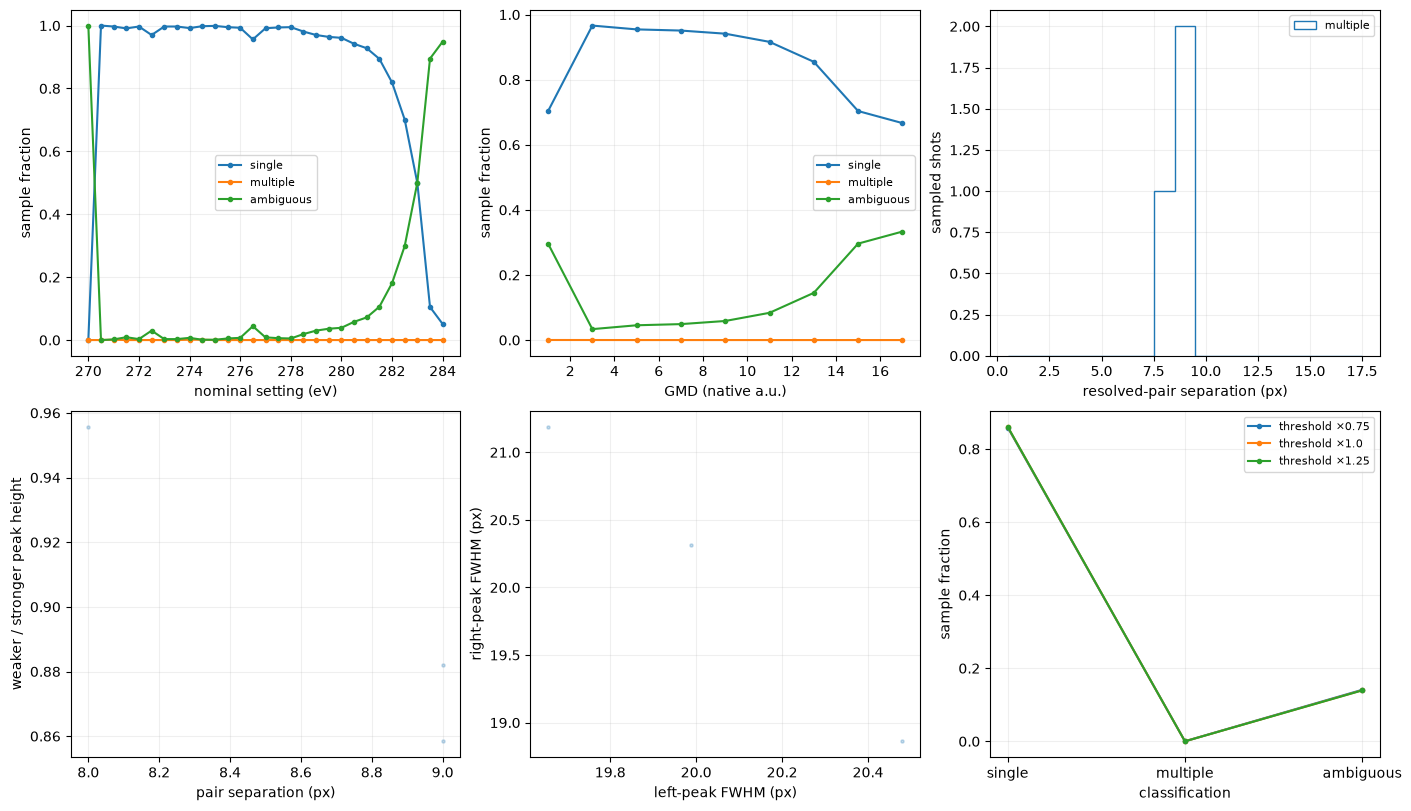

In [126]:
# Classification fractions, pair metrics and existing threshold sensitivity
(fig, ax) = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
resolved = fel_table['classification'] == 'multiple'
for label in ('single', 'multiple', 'ambiguous'):
    for (a, key, edges) in ((ax[0, 0], 'nominal_eV', np.unique(fel_table['nominal_eV'])),
        (ax[0, 1], 'gmd', FEL_GMD_EDGES)):
        if key == 'nominal_eV':
            groups = [fel_table[key] == e for e in edges]
            xx = edges
        else:
            groups = [(fel_table[key] >= lo) & (fel_table[key] < hi) for (lo,
                hi) in zip(edges[:-1], edges[1:])]
            xx = (np.asarray(edges[:-1]) + edges[1:]) / 2
        a.plot(xx, [np.mean(fel_table['classification'][m] == label) if m.any() else np.nan for m in groups],
            '.-', label=label)
    separations = fel_table['sep'][resolved & (fel_table['classification'] == label) & np.isfinite(fel_table['sep'])]
    if len(separations):
        ax[0, 2].hist(separations, bins=np.arange(0.5, fel_preview['config'].double_peak_kwargs['max_distance_px'] + 1.5),
            histtype='step', label=label)
ax[1, 0].scatter(fel_table['sep'][resolved], fel_table['second_ratio'][resolved], s=5, alpha=0.25)
ax[1, 1].scatter(fel_table['pair_width1_px'][resolved], fel_table['pair_width2_px'][resolved],
    s=5, alpha=0.25)
if not resolved.any():
    for empty in (ax[0, 2], ax[1, 0], ax[1, 1]):
        empty.text(0.5, 0.5, 'No resolved pair in bounded sample',
            ha='center', transform=empty.transAxes, fontsize=9)

# Classification fractions, pair metrics and existing threshold sensitivity (continued)
for factor in (0.75, 1.0, 1.25):
    cfg = fel.FELConfig(**asdict(fel_preview['config']))
    cfg.double_peak_kwargs = dict(cfg.double_peak_kwargs)
    for key in ('min_prom_sigma', 'min_height_sigma'):
        cfg.double_peak_kwargs[key] *= factor
    (labels, _, _) = fel.classify(fel_preview['spectra'], cfg, fel_preview['sigma_raw'])
    ax[1, 2].plot(['single', 'multiple', 'ambiguous'], [np.mean(labels == l) for l in ('single',
        'multiple', 'ambiguous')], '.-', label=f'threshold ×{factor}')
for a in ax[0, :2]:
    a.legend(fontsize=8)
if resolved.any():
    ax[0, 2].legend(fontsize=8)
ax[1, 2].legend(fontsize=8)
for (a, xlabel, ylabel) in zip(ax.flat, ('nominal setting (eV)', 'GMD (native a.u.)',
    'resolved-pair separation (px)', 'pair separation (px)', 'left-peak FWHM (px)',
    'classification'), ('sample fraction', 'sample fraction', 'sampled shots',
    'weaker / stronger peak height', 'right-peak FWHM (px)', 'sample fraction')):
    a.set(xlabel=xlabel, ylabel=ylabel)
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

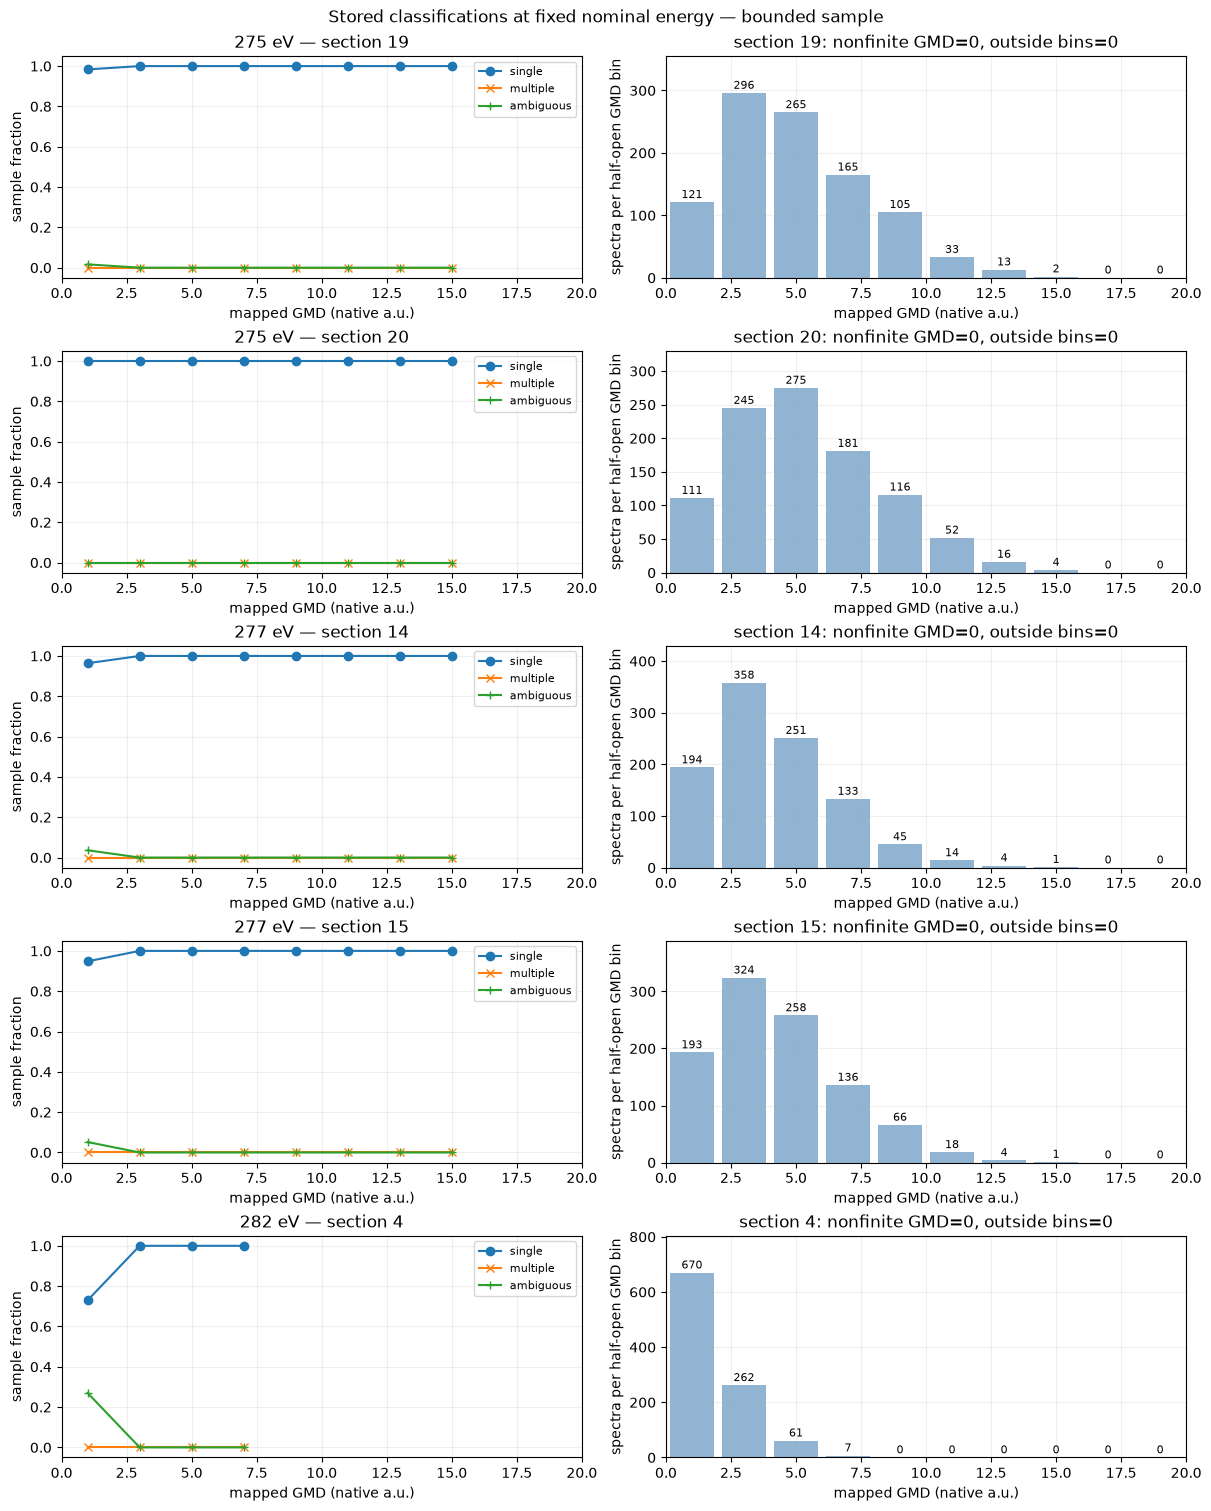

In [127]:
# Fixed-energy classification: finite GMD, no additional spectrum/quality cuts.
edges = np.asarray(FEL_GMD_EDGES, dtype=float)
if edges.ndim != 1 or len(edges) < 2 or not np.all(np.isfinite(edges)) or not np.all(np.diff(edges) > 0):
    raise ValueError('GMD edges must be finite and strictly increasing')
fig, ax = plt.subplots(len(fel_fixed_sections), 2, figsize=(12, 3*len(fel_fixed_sections)),
                       squeeze=False, constrained_layout=True)
fel_fixed_bins = {}
for (section, energy), axes in zip(fel_fixed_sections, ax):
    mask = fel_table['section_index'] == section
    gmd = fel_table['gmd'][mask]
    labels = fel_table['classification'][mask]
    classes = ('single', 'multiple', 'ambiguous')
    if not np.all(np.isin(labels, classes)):
        raise ValueError('Unexpected stored classification label')
    groups = [(gmd >= lo) & (gmd < hi) for lo, hi in zip(edges[:-1], edges[1:])]
    counts = np.array([group.sum() for group in groups])
    fractions = {label: np.divide([np.sum(group & (labels == label)) for group in groups],
                 counts, out=np.full(len(counts), np.nan), where=counts > 0) for label in classes}
    nonfinite = int(np.sum(~np.isfinite(gmd)))
    outside = int(np.sum(np.isfinite(gmd) & ((gmd < edges[0]) | (gmd >= edges[-1]))))
    fel_fixed_bins[section] = dict(counts=counts, fractions=fractions, edges=edges,
                                   nonfinite=nonfinite, outside=outside)
    xx = (edges[:-1]+edges[1:])/2
    for label, marker in zip(classes, ('o', 'x', '+')):
        axes[0].plot(xx, fractions[label], marker+'-', label=label)
    axes[0].set(title=f'{energy:g} eV — section {section}', ylim=(-.05, 1.05),
                xlabel='mapped GMD (native a.u.)', ylabel='sample fraction')
    axes[0].legend(fontsize=8)
    axes[1].bar(xx, counts, width=np.diff(edges)*.85, color='steelblue', alpha=.6)
    for x, count in zip(xx, counts):
        axes[1].annotate(str(count), (x, count), xytext=(0, 3), textcoords='offset points',
            ha='center', fontsize=8)
    axes[1].margins(y=.2)
    axes[1].set(title=f'section {section}: nonfinite GMD={nonfinite}, outside bins={outside}',
                xlabel='mapped GMD (native a.u.)', ylabel='spectra per half-open GMD bin')
    for axis in axes:
        axis.set_xlim(edges[0], edges[-1])
        axis.grid(alpha=.2)
fig.suptitle('Stored classifications at fixed nominal energy — bounded sample')
plt.show()

### Historical rejected spectra: same-shot classifier check

These are the **12 highest-score examples from the 61-rejection figure in A**,
recovered from measured `run58794_static_xas.h5`, not from a good/accepted-only product.
The one-time search used 4,096-row blocks and only the original finite/peak≥1000/GMD≤10
selection and double-peak detector: 1,164,240 recorded/finite → 573,622 peak-selected →
556,380 GMD-selected → 61 rejected. No XAS curves, centres or HDF5 products were regenerated.
The code below rereads **only these 12 rows** and checks their stored identities.
Indices are zero-based; row ranges in the recovery were half-open `[0,n_shots)`.

Provenance: baseline `e3dfa92bf5669a882d67dc5e772e915e4638d645`,
`analysis/scripts/static_xas_analysis.py::preprocess_shots_for_peakfinding`,
`detect_double_peaks_pairscan`, `prepare_proxy_shots`, `plot_double_peak_examples`;
`analysis/notebooks/xas_static_5mmol_simple.ipynb` cells 2/7/13 (zero-based, Markdown included).
Current local main `f940ee05ddc9fbbd2b0faa95cc25085608792323` moved that notebook to
`analysis/notebooks/xas_static/`; its saved text also reports 61, but saved energies
predate the wavelength-based labels. The older baseline's saved text (33) and figure
(35) are inconsistent, and other old notebooks mix run labels. Neither filenames nor
old energy labels establish identity. Here file `run_no`, `/ml/run_id`, section, source
row, train ID and both stored pulse indices agree. For this product roll=0, GOTTHARD
indices are raw frame indices; the GMD indices are stored associations, not independent
proof of physical synchronization. No run or energy relabelling is applied.

Both algorithms and parameters remain unchanged. The comparison freezes the original
pair settings (including default width 1–40 px); preprocessing is 15th-percentile baseline,
nonnegative clipping and Savitzky–Golay 9/2. The new `fel.classify` uses the same pair
detector plus reliability SNR≥5 with noise=max(shot MAD-difference noise, median stored
raw sigma within ±5 pixels of the smoothed maximum), a positive signal and an interior
maximum. A failed reliability gate gives **ambiguous**, even for a validated pair.
This selected example set cannot estimate classifier accuracy or full-run class fractions.
Recovery identities, per-shot metrics and verification are in
`validation/notebook03_classifier_20261021/`.

**Observed comparison (measured spectra; unchanged parameters):**

| Population | Historical double-peak rejections | New single | New multiple | New ambiguous |
|---|---:|---:|---:|---:|
| Displayed top 12 | 12 | 0 | 12 | 0 |
| All recovered rejections | 61 | 0 | 61 | 0 |

There are **no disagreements** here: all spectra have a validated pair, positive signal,
an interior smoothed maximum and reliability SNR≥5 (minimum 33.94 over all 61;
38.25–149.16 in the displayed 12). The extra reliability/endpoint criteria therefore
change no outcomes in this population. This does not test missed multiple peaks among
historically accepted shots. Re-rendering the recovered top 12 with the unchanged
historical plot reproduces A's saved PNG **pixel for pixel** (maximum pixel difference 0),
including score order, lineouts, pair markers and labels. The earlier 33/35 saved outputs
are a separate, inconsistent execution state and are not claimed to be recovered.


In [128]:
# Fixed historical comparison, independent of the preview sampling/display controls.
import h5py
import pandas as pd
comparison_input = path_config.XAS_STATIC_DIR / 'run58794_static_xas.h5'
comparison_cfg = fel.FELConfig(input_h5=comparison_input,
    classification_snr=5., baseline_quantile=.15, sg_window=9, sg_poly=2,
    double_peak_kwargs=dict(min_distance_px=3, max_distance_px=17,
        min_prom_sigma=2.5, min_height_sigma=2., min_rel_peak_height=.35,
        min_second_ratio=.05, min_bridge_drop=.015, min_split_sigma=.75))
# Score order from A: (section, original product row, train ID, GOTTHARD frame, GMD pulse).
comparison_ids = [(18, 30972, 2657646331, 22, 12), (18, 33822, 2657646438, 22, 12), (29, 27463, 2657664709, 23, 13), (17, 18577, 2657643785, 17, 7), (24, 18647, 2657655067, 27, 17), (28, 39525, 2657663222, 25, 15), (29, 2816, 2657663886, 36, 26), (29, 2299, 2657663869, 29, 19), (1, 8515, 2657615219, 35, 25), (28, 9412, 2657662158, 32, 22), (25, 25617, 2657657076, 37, 27), (18, 12627, 2657645707, 37, 27)]
print('Comparison input:', comparison_input.resolve())
print('Unchanged comparison settings:', asdict(comparison_cfg))
with h5py.File(comparison_input, 'r') as h:
    required = ('vls', 'n_shots', 'vls_pixels', 'nominal_energies', 'gmd',
                'noise/vls_bg_sigma_global', 'ml/run_id', 'ml/train_id',
                'ml/section_index', 'ml/vls_bunch_index', 'ml/gmd_bunch_index')
    print('Comparison schema:', {key: (h[key].shape, str(h[key].dtype)) for key in required})
    if int(h.attrs['run_no']) != 58794 or int(h.attrs['vls_bunch_roll']) != 0:
        raise ValueError('Historical comparison acquisition differs')
    if h['vls'].ndim != 3 or h['vls_pixels'].shape != (h['vls'].shape[2],):
        raise ValueError('Expected VLS (section, padded shot, pixel)')
    comparison_pixels = h['vls_pixels'][:]
    comparison_sigma = h['noise/vls_bg_sigma_global'][:]
    comparison_spectra, comparison_rows = [], []
    for sec, row, train, frame, pulse in comparison_ids:
        if not 0 <= row < h['n_shots'][sec]:
            raise ValueError('Comparison row lies outside recorded population')
        for key, expected in (('run_id', 58794), ('section_index', sec), ('train_id', train),
                              ('vls_bunch_index', frame), ('gmd_bunch_index', pulse)):
            if int(h['ml/'+key][sec, row]) != expected:
                raise ValueError(f'Historical identity mismatch: {key}, section {sec}, row {row}')
        comparison_spectra.append(h['vls'][sec, row, :])
        comparison_rows.append(dict(run=58794, section=sec, row=row, train=train, frame=frame,
                                   gmd_pulse=pulse, nominal_eV=float(h['nominal_energies'][sec]),
                                   gmd=float(h['gmd'][sec, row])))
comparison_spectra = np.asarray(comparison_spectra)
if not np.all(np.isfinite(comparison_spectra)) or not all(
        np.isfinite(row['gmd']) and row['gmd'] <= 10 for row in comparison_rows) or not np.all(
        comparison_spectra.max(axis=1) >= 1000):
    raise ValueError('Historical preselection no longer matches')
comparison_corrected, comparison_smoothed, comparison_noise = fel.sxa.preprocess_shots_for_peakfinding(
    comparison_spectra, baseline_q=.15, sg_window=9, sg_poly=2)
comparison_pair = fel.sxa.detect_double_peaks_pairscan(comparison_corrected, comparison_smoothed,
    comparison_noise, **comparison_cfg.double_peak_kwargs)
comparison_labels, comparison_details, _ = fel.classify(
    comparison_spectra, comparison_cfg, comparison_sigma)
for i, row in enumerate(comparison_rows):
    reliability = comparison_details['classification_reliability_snr'][i]
    maximum = np.argmax(comparison_smoothed[i])
    reasons = []
    if not np.isfinite(reliability) or reliability < comparison_cfg.classification_snr:
        reasons.append('reliability SNR < 5 or unavailable')
    if maximum in (0, len(comparison_pixels)-1):
        reasons.append('endpoint maximum')
    if comparison_corrected[i].max() <= 0:
        reasons.append('nonpositive signal')
    row.update(historical_reject=bool(comparison_pair['is_candidate'][i]),
               classification=str(comparison_labels[i]),
               reliability_snr=float(reliability),
               shape_snr=float(comparison_details['shape_snr'][i]),
               sep_px=float(comparison_pair['sep'][i]),
               score=float(comparison_pair['score'][i]),
               reason='; '.join(reasons) if reasons else 'same validated pair')
if not comparison_pair['is_candidate'].all():
    raise ValueError('Recovered examples no longer reproduce historical rejection')
comparison_table = pd.DataFrame(comparison_rows)
print(comparison_table.to_string(index=False, float_format=lambda value: f'{value:.4g}'))
print('Same-shot outcomes:', comparison_table.groupby(['historical_reject', 'classification']).size().to_dict())


Comparison input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5
Unchanged comparison settings: {'input_h5': PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), 'good_h5': None, 'shots_per_section': 128, 'sections': None, 'gmd_dataset': 'ml/gmd_hall_channels', 'gmd_channel': 0, 'center_method': 'com', 'center_half_window': 5, 'historical_peak_threshold': 1000.0, 'historical_gmd_min': None, 'historical_gmd_max': 10.0, 'classification_snr': 5.0, 'preview_snr_threshold': 5.0, 'baseline_quantile': 0.15, 'sg_window': 9, 'sg_poly': 2, 'double_peak_kwargs': {'min_distance_px': 3, 'max_distance_px': 17, 'min_prom_sigma': 2.5, 'min_height_sigma': 2.0, 'min_rel_peak_height': 0.35, 'min_second_ratio': 0.05, 'min_bridge_drop': 0.015, 'min_split_sigma': 0.75}, 'geometry': {'source_to_grating_m': 0.85, 'grating_to_screen_m': 0.5429, 'incident_angle_deg': 86.78, 'groove_density_lines_per_mm': 1200.0, 'diffraction_o

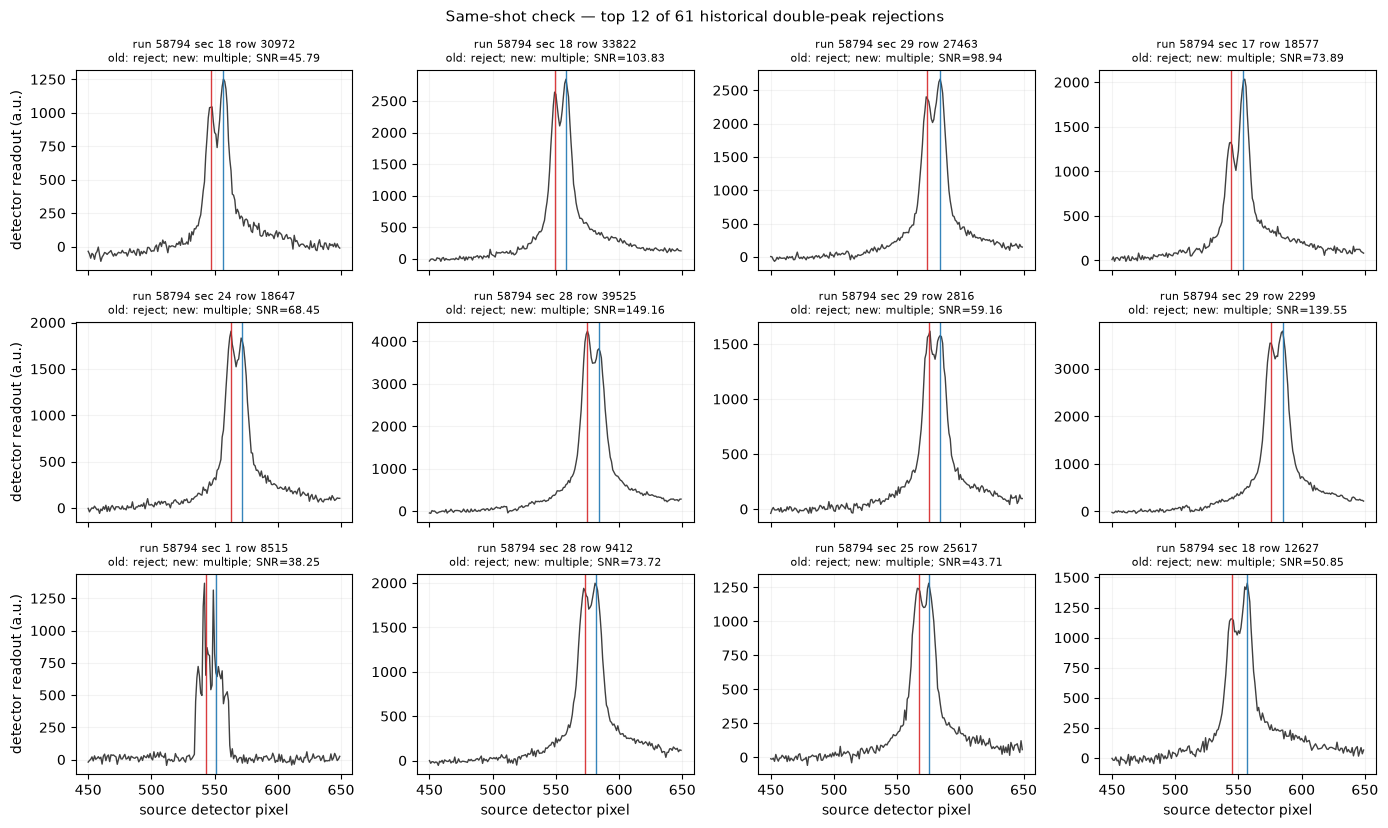

In [129]:
# Same spectra and pair markers as A; add verified shot identities and new labels.
fig, axes = plt.subplots(3, 4, figsize=(14, 8.4), sharex=True, squeeze=False)
for i, (axis, row) in enumerate(zip(axes.flat, comparison_rows)):
    axis.plot(comparison_pixels, comparison_spectra[i], color='0.25', lw=1.)
    for key, color in (('peak1_px', 'tab:red'), ('peak2_px', 'tab:blue')):
        axis.axvline(comparison_pixels[int(comparison_pair[key][i])], color=color, lw=1., alpha=.9)
    axis.set_title(f"run {row['run']} sec {row['section']} row {row['row']}\n"
                   f"old: reject; new: {row['classification']}; SNR={row['reliability_snr']:.2f}", fontsize=8)
    axis.grid(alpha=.15)
for axis in axes[-1]:
    axis.set_xlabel('source detector pixel')
for axis in axes[:, 0]:
    axis.set_ylabel('detector readout (a.u.)')
fig.suptitle('Same-shot check — top 12 of 61 historical double-peak rejections', fontsize=11)
fig.tight_layout()
plt.show()


## 5. Bandwidth, jitter, intensity and fluctuations

**ROI RMS width** is √[Σw(p−centroid)²/Σw], using nonnegative weights after the
explicit per-shot 15th-percentile baseline subtraction over the full stored detector
ROI. This diagnostic centroid differs from the historical local COM. RMS width is
sensitive to weak tails, residual pedestal, clipping, multiple lobes and finite ROI.
**FWHM** uses the connected strongest-peak lobe at half height on that unsmoothed
baseline-corrected profile; linear crossing positions determine the width. Missing
ROI crossings yield NaN. Merged peaks can broaden it; RMS and FWHM are not interchangeable
and no Gaussian conversion is imposed. Pair widths use the same definition at each lobe.

Integrated intensity is the **signed sum of the stored pixel samples**, retaining negative
readout values and upstream preprocessing. It is not incident energy, transmission or OD.
Histograms compare all finite metrics, historical nominal cuts and QC/SNR-preview cuts
on the same sample, printing each population. Centre residuals subtract each stored
section's sample median; SD versus nominal energy is shot-to-shot jitter in pixels,
not pooled scan spread, SEM or independently validated physical energy jitter.
No additional centre-quality filter is imposed: inspect weak-shot tails with section 6.
The mean/SD spectra retain fluctuations useful for later correlations; no full covariance
matrix is built. Section-specific drift and train correlations can broaden these statistics.

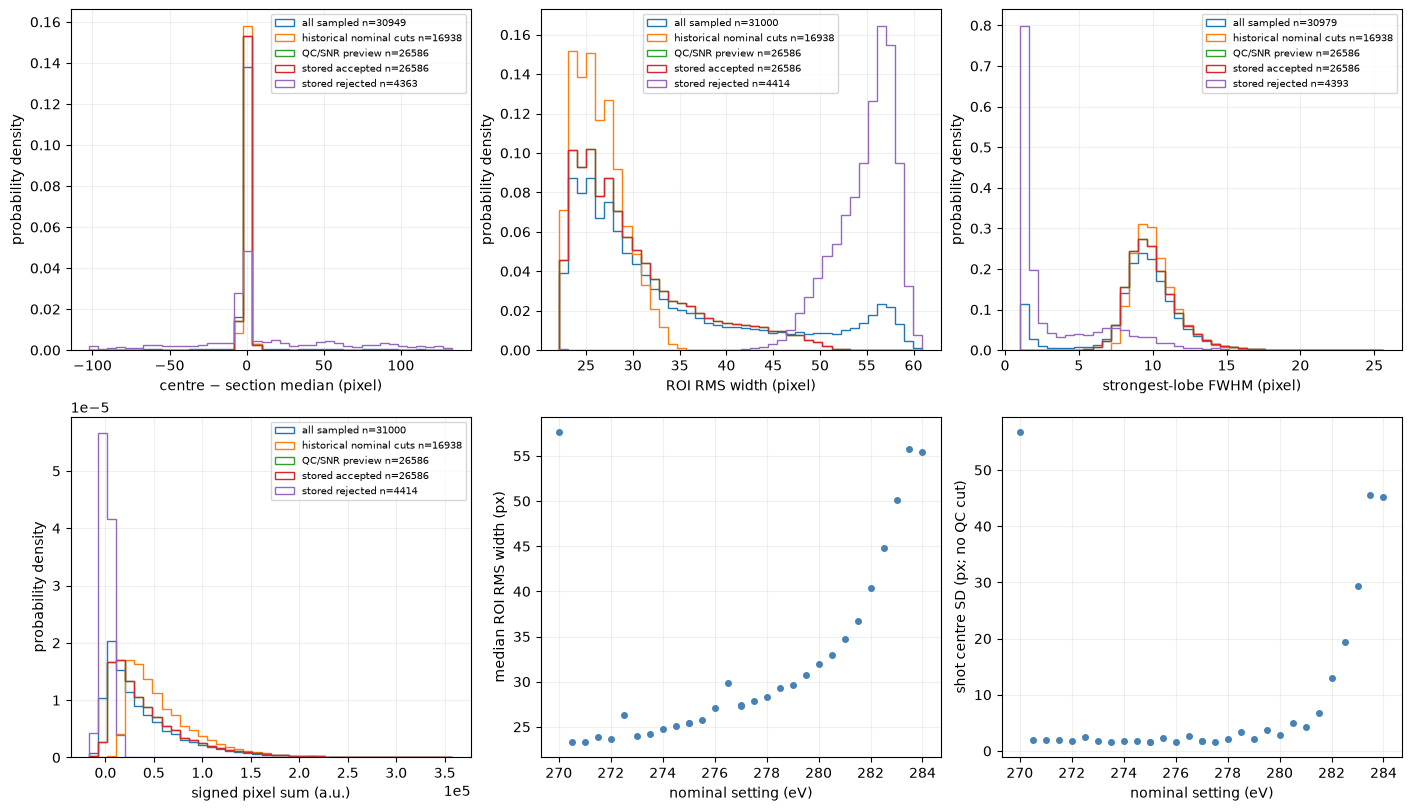

In [130]:
# Metric histograms and per-section width/jitter
(fig, ax) = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
jitter = np.full(len(fel_table['center_pixel']), np.nan)
for s in np.unique(fel_table['section_index']):
    m = fel_table['section_index'] == s
    c = fel_table['center_pixel'][m]
    if np.isfinite(c).any():
        jitter[m] = c - np.nanmedian(c)
for (key, a) in zip(('center_pixel', 'rms_width_px', 'fwhm_px', 'intensity_signed_sum'), ax.flat):
    values = jitter if key == 'center_pixel' else fel_table[key]
    finite_values = values[np.isfinite(values)]
    bins = np.histogram_bin_edges(finite_values, bins=40) if len(finite_values) else np.arange(2)
    populations = [(np.ones(len(values), bool), 'all sampled'), (fel_table['historical_nominal_keep'],
        'historical nominal cuts'), (fel_table['snr_preview_keep'], 'QC/SNR preview')]
    if np.any(fel_table['good_accepted'] >= 0):
        populations += [(fel_table['good_accepted'] == 1, 'stored accepted'),
            (fel_table['good_accepted'] == 0, 'stored rejected')]
    for (mask, label) in populations:
        data = values[mask & np.isfinite(values)]
        if len(data):
            a.hist(data, bins=bins, density=True, histtype='step', label=f'{label} n={len(data)}')
    labels = dict(center_pixel='centre − section median (pixel)', rms_width_px='ROI RMS width (pixel)',
        fwhm_px='strongest-lobe FWHM (pixel)', intensity_signed_sum='signed pixel sum (a.u.)')
    a.set(xlabel=labels[key], ylabel='probability density')
    a.legend(fontsize=7)
    if key == 'intensity_signed_sum':
        a.ticklabel_format(axis='x', style='sci', scilimits=(-3, 4))

# Metric histograms and per-section width/jitter (continued)
for s in np.unique(fel_table['section_index']):
    m = fel_table['section_index'] == s
    for (a, key) in ((ax[1, 1], 'rms_width_px'), (ax[1, 2], 'center_pixel')):
        values = fel_table[key][m]
        values = values[np.isfinite(values)]
        if len(values) > 1:
            y = np.std(values, ddof=1) if key == 'center_pixel' else np.median(values)
            a.plot(fel_table['nominal_eV'][m][0], y, 'o', color='steelblue', ms=4)
ax[1, 1].set(xlabel='nominal setting (eV)', ylabel='median ROI RMS width (px)')
ax[1, 2].set(xlabel='nominal setting (eV)', ylabel='shot centre SD (px; no QC cut)')
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

Selection: QC/SNR preview + single-peaked; minimum 20 selected spectra for statistics
Section   Energy  Sampled   QC/SNR    Used   FWHM med  Centre SD    MAD SD
     30  270.000     1000        0       0        nan        nan       nan
     29  270.500     1000      996     996      11.81       1.89      2.07
     28  271.000     1000      996     995      11.87       1.96      1.62
     27  271.500     1000      988     988      11.11       1.86      1.59
     26  272.000     1000      996     996      10.82       1.74      1.42
     25  272.500     1000      963     962      10.63       1.71      1.48
     24  273.000     1000      990     989      10.90       1.78      1.56
     23  273.500     1000      996     996      10.13       1.59      1.51
     22  274.000     1000      993     991      10.01       1.74      1.58
     21  274.500     1000      998     996      10.15       1.72      1.58
     19  275.000     1000      998     998      10.27       1.63      1.56
     20  275.0

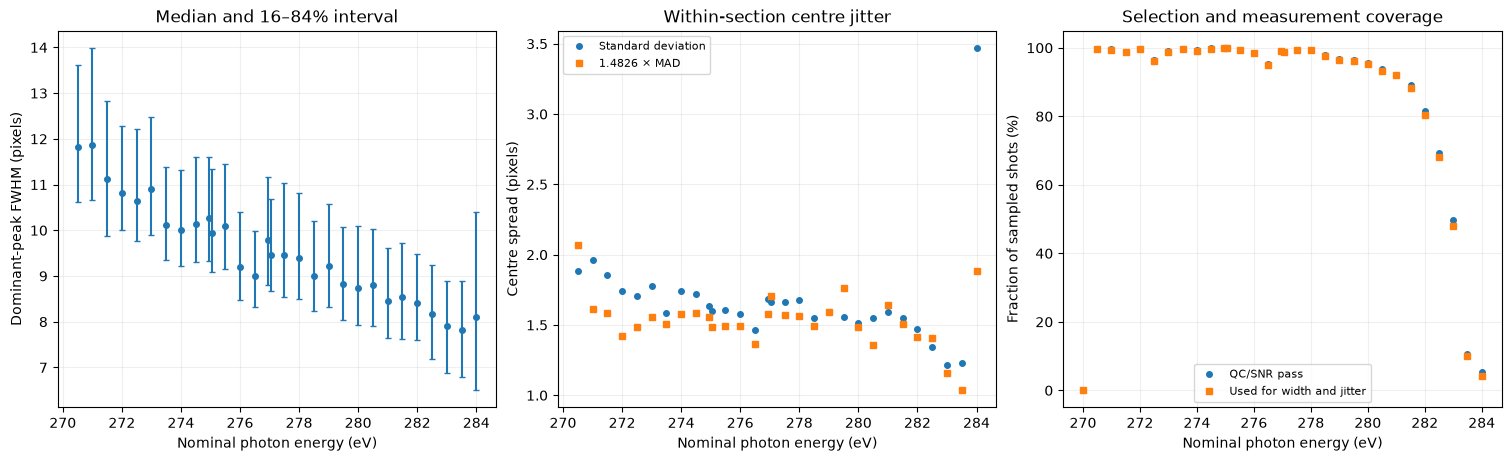

In [134]:
# --- Section 5 extension: reliable spectral bandwidth and centre jitter ---
# Uses the existing bounded preview; no new HDF5 reads.
REQUIRE_SINGLE_PEAK = True
MIN_RELIABLE_SHOTS = 20

section = np.asarray(fel_table['section_index'])
energy = np.asarray(fel_table['nominal_eV'], dtype=float)
centre = np.asarray(fel_table['center_pixel'], dtype=float)
fwhm = np.asarray(fel_table['fwhm_px'], dtype=float)
qc_snr = np.asarray(fel_table['snr_preview_keep'], dtype=bool)
classification = np.asarray(fel_table['classification'])

# One consistent population for bandwidth and jitter; missing/invalid widths are excluded.
reliable = qc_snr & np.isfinite(centre) & np.isfinite(fwhm) & (fwhm > 0)
if REQUIRE_SINGLE_PEAK:
    reliable &= classification == 'single'

results = []
for s in np.unique(section):
    in_section = section == s
    selected = in_section & reliable
    n_total, n_qc, n_used = in_section.sum(), (in_section & qc_snr).sum(), selected.sum()
    row = dict(section=int(s), energy=float(np.median(energy[in_section])),
               n_total=int(n_total), n_qc=int(n_qc), n_used=int(n_used),
               qc_fraction=n_qc/n_total, usable_fraction=n_used/n_total,
               fwhm_med=np.nan, fwhm_lo=np.nan, fwhm_hi=np.nan,
               centre_sd=np.nan, centre_mad=np.nan)

    if n_used >= MIN_RELIABLE_SHOTS:
        widths, centres = fwhm[selected], centre[selected]
        row['fwhm_med'] = float(np.median(widths))
        row['fwhm_lo'], row['fwhm_hi'] = np.percentile(widths, [16, 84])
        row['centre_sd'] = float(np.std(centres, ddof=1))
        row['centre_mad'] = float(1.4826*np.median(np.abs(centres-np.median(centres))))
    results.append(row)

results.sort(key=lambda r: (r['energy'], r['section']))
print(f"Selection: QC/SNR preview{' + single-peaked' if REQUIRE_SINGLE_PEAK else ''}; "
      f'minimum {MIN_RELIABLE_SHOTS} selected spectra for statistics')
print(f"{'Section':>7} {'Energy':>8} {'Sampled':>8} {'QC/SNR':>8} {'Used':>7} "
      f"{'FWHM med':>10} {'Centre SD':>10} {'MAD SD':>9}")
for r in results:
    print(f"{r['section']:7d} {r['energy']:8.3f} {r['n_total']:8d} {r['n_qc']:8d} "
          f"{r['n_used']:7d} {r['fwhm_med']:10.2f} {r['centre_sd']:10.2f} "
          f"{r['centre_mad']:9.2f}")

# Separate repeated nominal energies slightly in the display only.
x_plot = np.array([r['energy'] for r in results])
for e in np.unique(x_plot):
    ids = np.flatnonzero(np.isclose(x_plot, e, rtol=0, atol=1e-6))
    if len(ids) > 1:
        x_plot[ids] += np.linspace(-0.05, 0.05, len(ids))

med = np.array([r['fwhm_med'] for r in results])
lo = np.array([r['fwhm_lo'] for r in results])
hi = np.array([r['fwhm_hi'] for r in results])
sd = np.array([r['centre_sd'] for r in results])
mad = np.array([r['centre_mad'] for r in results])
qc_frac = np.array([r['qc_fraction'] for r in results])
used_frac = np.array([r['usable_fraction'] for r in results])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

valid = np.isfinite(med)
ax[0].errorbar(x_plot[valid], med[valid],
               yerr=np.vstack((med[valid]-lo[valid], hi[valid]-med[valid])),
               fmt='o', ms=4, capsize=2)
ax[0].set(xlabel='Nominal photon energy (eV)', ylabel='Dominant-peak FWHM (pixels)',
          title='Median and 16–84% interval')

ax[1].plot(x_plot, sd, 'o', ms=4, label='Standard deviation')
ax[1].plot(x_plot, mad, 's', ms=4, label='1.4826 × MAD')
ax[1].set(xlabel='Nominal photon energy (eV)', ylabel='Centre spread (pixels)',
          title='Within-section centre jitter')
ax[1].legend(fontsize=8)

ax[2].plot(x_plot, 100*qc_frac, 'o', ms=4, label='QC/SNR pass')
ax[2].plot(x_plot, 100*used_frac, 's', ms=4, label='Used for width and jitter')
ax[2].set(xlabel='Nominal photon energy (eV)', ylabel='Fraction of sampled shots (%)',
          title='Selection and measurement coverage', ylim=(-5, 105))
ax[2].legend(fontsize=8)

for a in ax:
    a.grid(alpha=0.2)
plt.show()

Common GMD comparison: 1–2 a.u.
  Energy  Section  Selected  In range   Median FWHM
   271.0       28       995       109         11.76
   274.0       22       991       186          9.89
   282.0        4       803       322          8.33


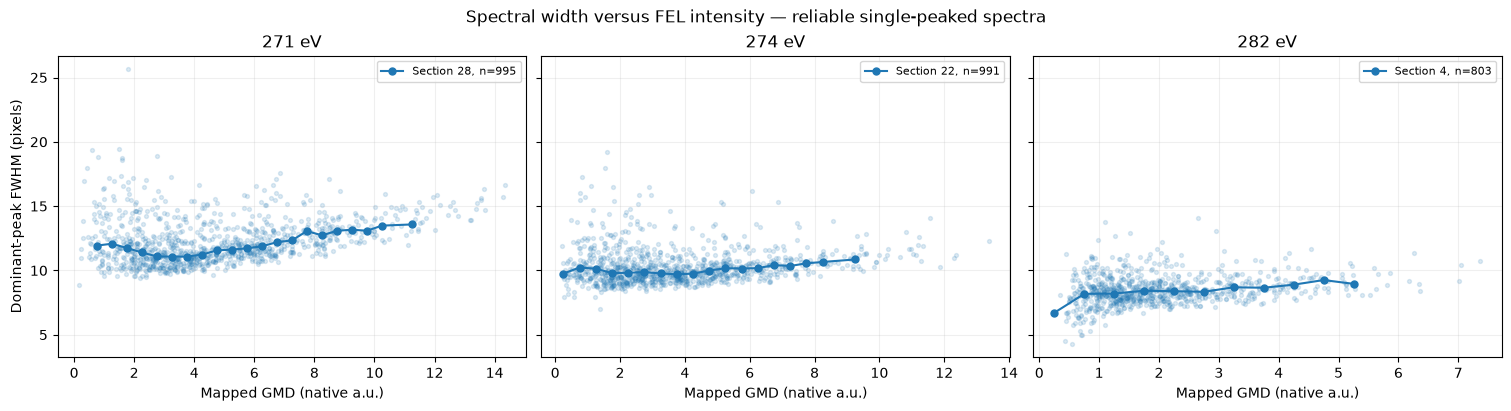

In [139]:
# --- Dominant-peak FWHM versus GMD at fixed photon energy ---
FWHM_ENERGIES_EV = (271., 274., 282.)
GMD_BIN_WIDTH = 0.5
MIN_BIN_SHOTS = 10
COMMON_GMD_RANGE = (1., 2.)  # native GMD a.u.; comparison across energies

t = fel_table
gmd = np.asarray(t['gmd'], dtype=float)
fwhm = np.asarray(t['fwhm_px'], dtype=float)
energy = np.asarray(t['nominal_eV'], dtype=float)
section = np.asarray(t['section_index'])

reliable = (np.asarray(t['snr_preview_keep'], dtype=bool) &
            (np.asarray(t['classification']) == 'single') &
            np.isfinite(t['center_pixel']) & np.isfinite(fwhm) &
            (fwhm > 0) & np.isfinite(gmd))

fig, ax = plt.subplots(1, len(FWHM_ENERGIES_EV), figsize=(15, 4), sharey=True, constrained_layout=True)

print(f"Common GMD comparison: {COMMON_GMD_RANGE[0]:g}–{COMMON_GMD_RANGE[1]:g} a.u.")
print(f"{'Energy':>8} {'Section':>8} {'Selected':>9} {'In range':>9} {'Median FWHM':>13}")

for a, e in zip(np.atleast_1d(ax), FWHM_ENERGIES_EV):
    sections = np.unique(section[np.isclose(energy, e, atol=1e-6, rtol=0)])
    if not len(sections):
        raise ValueError(f'No section at {e:g} eV')

    for j, s in enumerate(sections):
        m = reliable & (section == s)
        x, y = gmd[m], fwhm[m]
        if not len(x):
            continue

        color = f'C{j}'
        a.scatter(x, y, s=8, alpha=0.15, color=color)
        edges = np.arange(0, max(2., np.ceil(x.max()/GMD_BIN_WIDTH)*GMD_BIN_WIDTH) + GMD_BIN_WIDTH,
                          GMD_BIN_WIDTH)
        centres, medians = [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            values = y[(x >= lo) & (x < hi)]
            if len(values) >= MIN_BIN_SHOTS:
                centres.append((lo + hi)/2)
                medians.append(np.median(values))
        a.plot(centres, medians, 'o-', ms=5, color=color, label=f'Section {s}, n={len(x)}')

        common = (x >= COMMON_GMD_RANGE[0]) & (x < COMMON_GMD_RANGE[1])
        median = np.median(y[common]) if common.any() else np.nan
        print(f'{e:8.1f} {s:8d} {len(x):9d} {common.sum():9d} {median:13.2f}')

    a.set(xlabel='Mapped GMD (native a.u.)', title=f'{e:g} eV')
    a.grid(alpha=0.2)
    a.legend(fontsize=8)

ax[0].set_ylabel('Dominant-peak FWHM (pixels)')
fig.suptitle('Spectral width versus FEL intensity — reliable single-peaked spectra')
plt.show()

272 eV | section 26 | sampled index 123 | original HDF5 row 4384 | GMD 3.011 | classification single | FWHM 10.86 px
277.5 eV | section 13 | sampled index 123 | original HDF5 row 4395 | GMD 2.078 | classification single | FWHM 8.21 px
283 eV | section 2 | sampled index 123 | original HDF5 row 4801 | GMD 1.414 | classification single | FWHM 8.92 px


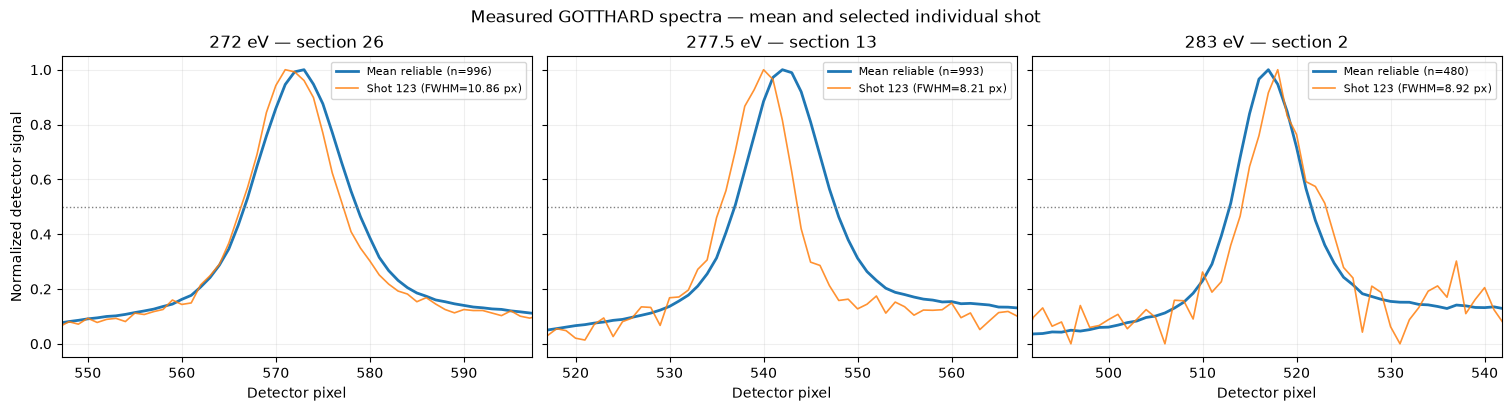

In [141]:
# --- Compare average spectra with an individually selected shot ---
SPECTRUM_ENERGIES_EV = (272., 277.5, 283.)
SHOT_INDEX = 123  # Index within the sampled shots of each section (0–999)
DISPLAY_HALF_WIDTH_PX = 25

t = fel_table
spectra = fel_preview['spectra']
pixels = np.asarray(fel_preview['pixels'])
section = np.asarray(t['section_index'])
energy = np.asarray(t['nominal_eV'], dtype=float)
fwhm = np.asarray(t['fwhm_px'], dtype=float)
centre = np.asarray(t['center_pixel'], dtype=float)

reliable = (np.asarray(t['snr_preview_keep'], dtype=bool) &
            (np.asarray(t['classification']) == 'single') &
            np.isfinite(centre) & np.isfinite(fwhm) & (fwhm > 0))

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)

for a, e in zip(ax, SPECTRUM_ENERGIES_EV):
    sections = np.unique(section[np.isclose(energy, e, atol=1e-6, rtol=0)])
    if len(sections) != 1:
        raise ValueError(f'Expected one section at {e:g} eV, found {sections}')

    s = sections[0]
    section_ids = np.flatnonzero(section == s)
    if not 0 <= SHOT_INDEX < len(section_ids):
        raise ValueError(f'SHOT_INDEX must be between 0 and {len(section_ids)-1} for section {s}')

    i = section_ids[SHOT_INDEX]
    ids = np.flatnonzero((section == s) & reliable)
    if not len(ids):
        raise ValueError(f'No reliable spectra at {e:g} eV')

    mean_spectrum = np.mean(spectra[ids], axis=0)
    individual_spectrum = spectra[i]

    # Baseline subtraction and normalization for display only; no smoothing.
    mean_corrected = np.clip(mean_spectrum - np.percentile(mean_spectrum, 15), 0, None)
    individual_corrected = np.clip(individual_spectrum - np.percentile(individual_spectrum, 15), 0, None)

    mean_normalized = mean_corrected / mean_corrected.max() if mean_corrected.max() > 0 else np.zeros_like(mean_corrected)
    individual_normalized = (individual_corrected / individual_corrected.max()
                             if individual_corrected.max() > 0 else np.zeros_like(individual_corrected))

    a.plot(pixels, mean_normalized, lw=2, label=f'Mean reliable (n={len(ids)})')
    a.plot(pixels, individual_normalized, lw=1.2, alpha=0.85,
           label=f'Shot {SHOT_INDEX} (FWHM={fwhm[i]:.2f} px)')
    a.axhline(0.5, color='gray', ls=':', lw=1)

    centre_median = np.median(centre[ids])
    a.set_xlim(centre_median - DISPLAY_HALF_WIDTH_PX, centre_median + DISPLAY_HALF_WIDTH_PX)
    a.set(xlabel='Detector pixel', title=f'{e:g} eV — section {s}')
    a.grid(alpha=0.2)
    a.legend(fontsize=8)

    print(f'{e:g} eV | section {s} | sampled index {SHOT_INDEX} | '
          f"original HDF5 row {t['source_shot_index'][i]} | "
          f"GMD {t['gmd'][i]:.3f} | "
          f"classification {t['classification'][i]} | "
          f"FWHM {fwhm[i]:.2f} px")

ax[0].set_ylabel('Normalized detector signal')
fig.suptitle('Measured GOTTHARD spectra — mean and selected individual shot')
plt.show()

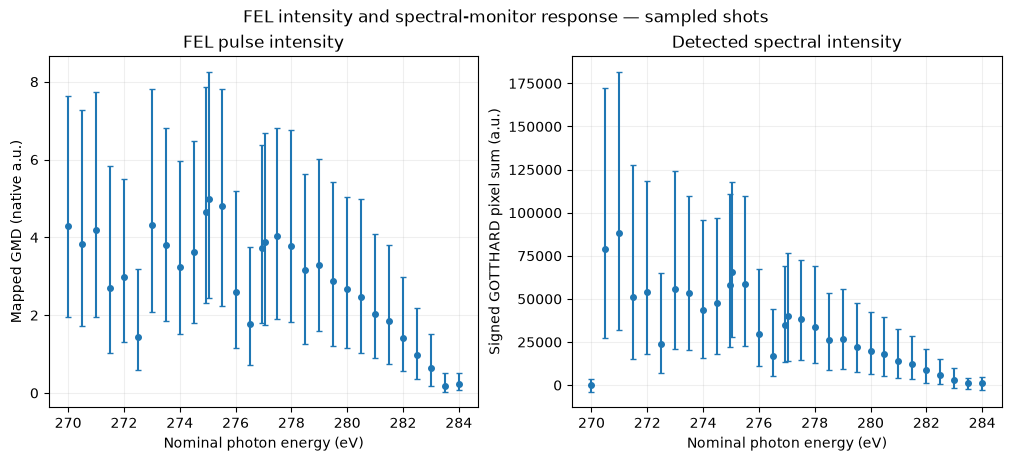

 Energy  Sec  Shots  GMD median   GOT median        Slope  Pearson r
  270.0   30   1000       4.303        299.1         39.6      0.024
  270.5   29   1000       3.841      78894.5      24185.7      0.976
  271.0   28   1000       4.186      88285.2      23891.2      0.975
  271.5   27   1000       2.692      51112.2      22876.1      0.978
  272.0   26   1000       2.983      54181.9      22775.3      0.976
  272.5   25   1000       1.433      23807.9      22555.4      0.975
  273.0   24   1000       4.331      56035.3      17041.1      0.956
  273.5   23   1000       3.796      53235.1      16719.7      0.958
  274.0   22   1000       3.239      43633.6      16307.3      0.961
  274.5   21   1000       3.631      47383.1      15675.4      0.955
  275.0   19   1000       4.654      57872.0      14466.2      0.953
  275.0   20   1000       4.979      65543.2      14315.0      0.945
  275.5   18   1000       4.801      58848.2      14115.3      0.953
  276.0   17   1000       2.606   

In [145]:
# --- FEL intensity and GOTTHARD response versus photon energy ---
# All finite sampled shots, with no SNR or single-peak selection.
MIN_FIT_SHOTS = 20

t = fel_table
section = np.asarray(t['section_index'])
energy = np.asarray(t['nominal_eV'], dtype=float)
gmd = np.asarray(t['gmd'], dtype=float)
signal = np.asarray(t['intensity_signed_sum'], dtype=float)

valid = np.isfinite(gmd) & np.isfinite(signal)
results = []

for s in np.unique(section):
    m = (section == s) & valid
    x, y = gmd[m], signal[m]
    e = float(np.median(energy[section == s]))

    row = dict(section=int(s), energy=e, n=len(x),
               gmd_med=np.nan, gmd_lo=np.nan, gmd_hi=np.nan,
               signal_med=np.nan, signal_lo=np.nan, signal_hi=np.nan,
               slope=np.nan, intercept=np.nan, r=np.nan)

    if len(x):
        row['gmd_med'] = np.median(x)
        row['gmd_lo'], row['gmd_hi'] = np.percentile(x, [16, 84])
        row['signal_med'] = np.median(y)
        row['signal_lo'], row['signal_hi'] = np.percentile(y, [16, 84])

    if len(x) >= MIN_FIT_SHOTS and np.std(x) > 1e-12:
        row['slope'], row['intercept'] = np.polyfit(x, y, 1)
        if np.std(y) > 1e-12:
            row['r'] = np.corrcoef(x, y)[0, 1]

    results.append(row)

results.sort(key=lambda r: (r['energy'], r['section']))

# Slight horizontal separation for repeated energies, display only.
xp = np.array([r['energy'] for r in results])
for e in np.unique(xp):
    ids = np.flatnonzero(np.isclose(xp, e, rtol=0, atol=1e-6))
    if len(ids) > 1:
        xp[ids] += np.linspace(-0.05, 0.05, len(ids))

def values(key):
    return np.array([r[key] for r in results], dtype=float)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

for a, prefix, ylabel, title in (
    (ax[0], 'gmd', 'Mapped GMD (native a.u.)', 'FEL pulse intensity'),
    (ax[1], 'signal', 'Signed GOTTHARD pixel sum (a.u.)', 'Detected spectral intensity'),
):
    med, lo, hi = (values(f'{prefix}_{k}') for k in ('med', 'lo', 'hi'))
    good = np.isfinite(med) & np.isfinite(lo) & np.isfinite(hi)
    a.errorbar(xp[good], med[good],
               yerr=[med[good]-lo[good], hi[good]-med[good]],
               fmt='o', ms=4, capsize=2)
    a.set(xlabel='Nominal photon energy (eV)', ylabel=ylabel,
          title=title)

for a in ax:
    a.grid(alpha=0.2)

fig.suptitle('FEL intensity and spectral-monitor response — sampled shots')
plt.show()

print(f"{'Energy':>7} {'Sec':>4} {'Shots':>6} {'GMD median':>11} "
      f"{'GOT median':>12} {'Slope':>12} {'Pearson r':>10}")
for r in results:
    print(f"{r['energy']:7.1f} {r['section']:4d} {r['n']:6d} "
          f"{r['gmd_med']:11.3f} {r['signal_med']:12.1f} "
          f"{r['slope']:12.1f} {r['r']:10.3f}")

## 6. Spectral quality and selection bias

Compare raw peak height ≥1000 alone, historical **nominal** peak/GMD cuts (finite spectra
and GMD, default GMD ≤10; no double rejection), the bounded finite/ML-QC/local-centre/SNR
preview and exact stored good decisions when available. Preview SNR is prominence above
the larger side-window 20th-percentile baseline divided by median stored raw-background
sigma within ±5 pixels of the maximum. Side windows [p−20,p−5) and [p+5,p+20) each
require ≥5 pixels. The reused source defaults are shown below, independent of the
classification's MAD noise estimate. SNR threshold is editable and diagnostic only.
Stored good decisions preserve the generating configuration even when preview settings change.

Use centre reliability cuts for centre-dependent questions separately from intensity,
mean-lineout or fluctuation populations. Rejected spectra can be weak but useful;
accepted/rejected means, individual examples and width/GMD scatter expose this possibility,
but do not establish usability for every downstream task. Fractions rejected are 1−accepted
for each known population; absent good decisions are unknown, not rejected. No filter is
applied globally. The mean/individual comparison uses the explicitly selected example section.

The existing run 58794 good product selected 897,048/1,164,240 spectra (77.05%); acceptance
is strongly energy-dependent, and its 270 eV section has only four accepted shots. Stored
counts below are **full-population metadata**; all GMD-dependent fractions/new metrics
are bounded previews. Those four shots do not establish representative 270 eV spectral
properties or a reliable calibration anchor. Rejected rows require the ordinary input:
selecting the good file itself gives accepted-only diagnostics and cannot measure rejection
bias. Good spectra are read from `vls`, never `vls_intercept_corrected*`; raw/corrected
integrals remain distinct in optional historical analyses. No good processor is run here.

In [131]:
print('SNR preview definition:', fel.rc.ProcessGoodConfig(input_h5=FEL.input_h5),
      'applied threshold:', FEL.preview_snr_threshold)
if fel_preview['good'] is not None:
    good_meta = fel_preview['good']
    print('Good source / selection GMD / stored QC:', good_meta['attrs']['source_h5'],
          good_meta['attrs'].get('processing_gmd_dataset'), good_meta['qc_attrs'])
    c = good_meta['counts']
    print('Stored full recorded/accepted:', int(c['recorded'].sum()), int(c['peak_keep'].sum()))
    for j in range(len(c['section'])):
        print('section / energy / recorded / accepted / rejected:', int(c['section'][j]),
              c['section_energy_eV'][j], int(c['recorded'][j]), int(c['peak_keep'][j]),
              int(c['recorded'][j]-c['peak_keep'][j]))
for key in ('historical_peak_keep','historical_nominal_keep','snr_preview_keep','good_accepted'):
    m = fel_table[key] >= 0
    print(key, 'known / accepted / rejected:', int(m.sum()), int(np.sum(fel_table[key][m]==1)),
          int(np.sum(fel_table[key][m]==0)))

SNR preview definition: ProcessGoodConfig(input_h5=PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), output_h5=None, use_ml_qc_ok=True, chunk_size=20000, energy_group_decimals=3, proxy_pixel_bin_width=1, energy_calibration_poly_order=1, energy_calibration_min_sections=4, peak_snr_threshold=5.0, prominence_inner_px=5, prominence_outer_px=20, prominence_baseline_percentile=20.0, sigma_half_window_px=5, center_half_window_px=5, min_side_pixels=5, gmd_source='hall') applied threshold: 5.0
Good source / selection GMD / stored QC: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5 ml/gmd_hall_channels[..., 0] {'center_half_window_px': np.int64(5), 'peak_snr_threshold': np.float64(5.0), 'prominence_baseline_percentile': np.float64(20.0), 'prominence_inner_px': np.int64(5), 'prominence_outer_px': np.int64(20)}
Stored full recorded/accepted: 1164240 897048
section / energy / recorded / accepted / rejected: 0 28

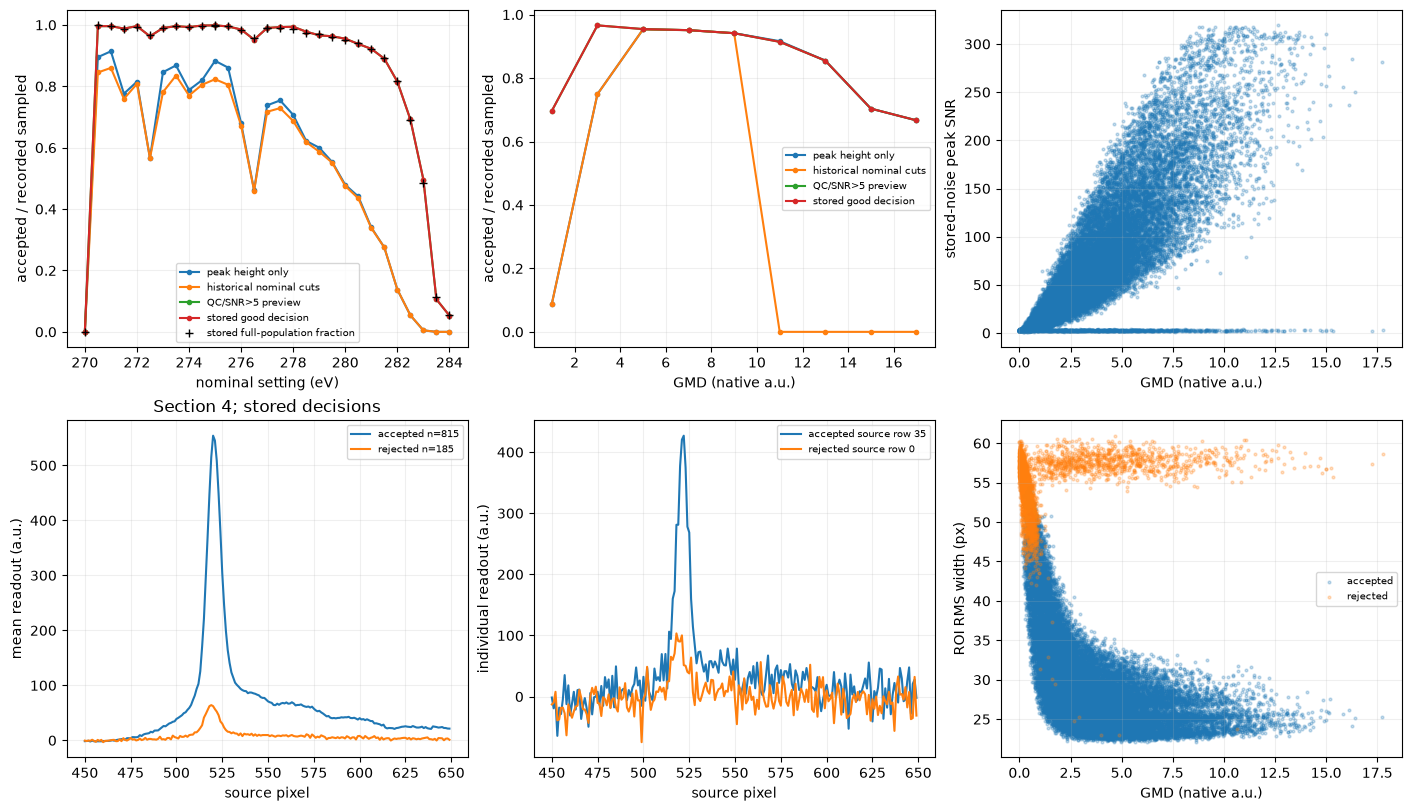

In [132]:
# Selection bias, means and displayed examples
section = FEL_EXAMPLE_SECTION
(fig, ax) = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for (key, label) in (('historical_peak_keep', 'peak height only'),
    ('historical_nominal_keep', 'historical nominal cuts'), ('snr_preview_keep',
    f"QC/SNR>{fel_preview['config'].preview_snr_threshold:g} preview"),
    ('good_accepted', 'stored good decision')):
    known = fel_table[key] >= 0
    for (a, x, bins) in ((ax[0, 0], fel_table['nominal_eV'], None),
        (ax[0, 1], fel_table['gmd'], FEL_GMD_EDGES)):
        xx = np.unique(x[np.isfinite(x)]) if bins is None else (np.asarray(bins[:-1]) + bins[1:]) / 2
        groups = [x == value for value in xx] if bins is None else [(x >= lo) & (x < hi) for (lo,
            hi) in zip(bins[:-1], bins[1:])]
        frac = [np.mean(fel_table[key][m & known].astype(bool)) if (m & known).any() else np.nan for m in groups]
        a.plot(xx, frac, '.-', label=label)
good = fel_preview['good']
if good:
    c = good['counts']
    ax[0, 0].plot(c['section_energy_eV'], np.divide(c['peak_keep'],
        c['recorded'], out=np.full_like(c['recorded'], np.nan), where=c['recorded'] > 0),
        'k+', label='stored full-population fraction')
ax[0, 2].scatter(fel_table['gmd'], fel_table['peak_snr'], s=4, alpha=0.25)
decision = fel_table['good_accepted'] if np.any(fel_table['good_accepted'] >= 0) else fel_table['snr_preview_keep'].astype(int)
for (value, label) in ((1, 'accepted'), (0, 'rejected')):
    m = (fel_table['section_index'] == section) & (decision == value) & fel_table['finite_spectrum']
    if m.any():
        ax[1, 0].plot(fel_preview['pixels'], fel_preview['spectra'][m].mean(0), label=f'{label} n={m.sum()}')
    ids = np.flatnonzero(m)[:FEL_QUALITY_SPECTRA_PER_GROUP]
    for i in ids:
        ax[1, 1].plot(fel_preview['pixels'], fel_preview['spectra'][i],
            label=f"{label} source row {fel_table['source_shot_index'][i]}")
    ax[1, 2].scatter(fel_table['gmd'][decision == value], fel_table['rms_width_px'][decision == value],
        s=4, alpha=0.25, label=label)
for a in (ax[0, 0], ax[0, 1], ax[1, 0], ax[1, 1], ax[1, 2]):
    a.legend(fontsize=7)
for (a, x, y) in zip(ax.flat, ('nominal setting (eV)', 'GMD (native a.u.)',
    'GMD (native a.u.)', 'source pixel', 'source pixel', 'GMD (native a.u.)'),
    ('accepted / recorded sampled', 'accepted / recorded sampled', 'stored-noise peak SNR',
    'mean readout (a.u.)', 'individual readout (a.u.)', 'ROI RMS width (px)')):
    a.set(xlabel=x, ylabel=y)
ax[1, 0].set_title(f'Section {section}; ' + ('stored decisions' if np.any(fel_table['good_accepted'] >= 0) else 'preview decisions'))
for axis in np.asarray(ax).flat:
    axis.grid(alpha=.2)
plt.show()

## 7. Shot metadata for delay/eTOF/ionTOF correlations

`fel_table` is a compact column dictionary, with run, section, product row, original
source row, train ID, stored GOTTHARD index, native GMD pulse index, recorded GMD,
centres, widths, signed intensity, quality masks and peak classification/metrics.
All masks remain columns; no source identity is lost. Source channel, input paths,
scientific settings and acquisition attributes are in `fel_preview` and the export sidecar.
Stored GOTTHARD indices use the product's **post-roll selection coordinate**; for run
58794 roll=0 they coincide with raw frames. No independent inverse roll is inferred
for other acquisitions: consult notebook 01 and the original acquired frame count.
Equal lengths or stored index differences are not proof of physical synchronization.

Export is disabled by default. To save this **small sampled** table, choose an explicit
existing project-local directory and set `FEL_EXPORT_CSV`; CSV and JSON provenance are
created exclusively and refuse overwrite. Saving does not create experimental HDF5.
Summary metrics cannot replace full pixel spectra for spectral-domain ghost imaging.

At beamtime: establish alignment (01), review background/calibration (02), then run
03 sections 1–6; inspect ambiguous spectra and energy-dependent acceptance before
choosing operating conditions. Retain section 7 identities for detector joins. To
estimate relative pump/probe contributions one needs experimentally justified arm
tags, resolved spectral components or a validated spectral model and response; a
combined spectrum alone cannot supply that ratio. Notebook 04 owns delay/fringe
diagnostics (resolution, fringe visibility and delay calibration); later notebook 05
can address detector joins, spectral correlations and ghost imaging. No complete
fringe retrieval, temporal-pulse assignment or ghost-imaging inversion is implemented here.

In [133]:
print('Retained table columns:', list(fel_table))
print('Rows retained (sample only):', len(fel_table['train_id']))
if FEL_EXPORT_CSV is not None:
    print('Saved:', fel.export_table(fel_preview, FEL_EXPORT_CSV, PROJECT_ROOT))
else:
    print('Export disabled. Full bounded spectra remain in fel_preview["spectra"].')

Retained table columns: ['train_id', 'run_id', 'section_index', 'vls_bunch_index', 'gmd_bunch_index', 'qc_ok', 'product_row', 'source_shot_index', 'nominal_eV', 'gmd', 'good_accepted', 'peak_snr', 'qc_center_pixel', 'finite_spectrum', 'historical_peak_keep', 'historical_nominal_keep', 'snr_preview_keep', 'intensity_signed_sum', 'center_pixel', 'peak_pixel', 'classification', 'n_peaks', 'sep', 'second_ratio', 'pair_width1_px', 'pair_width2_px', 'shape_snr', 'classification_reliability_snr', 'roi_centroid_pixel', 'rms_width_px', 'fwhm_px', 'geometry_eV', 'empirical_eV', 'geometry_qc_center_eV', 'empirical_qc_center_eV', 'empirical_extrapolated']
Rows retained (sample only): 31000
Export disabled. Full bounded spectra remain in fel_preview["spectra"].


## 8. Optional historical / secondary GOTTHARD XAS analyses

The original 63 cells follow in their original order, including all saved outputs.
Every original code body is preserved inside a section guard; the original source,
execution counts and metadata are also retained in the validation backup. Original
indices are recorded as `metadata.fel_original_cell_index`; use these for old manifests.
**Historical results/labels are archival, not the new experiment's molecular XAS workflow.**

`HISTORICAL_SECTIONS=set()` skips all historical code during Run All. To reproduce one
analysis, edit this set in section 1, then run section 8 in order. A/B use full-memory
loaders (previous peak RSS ~13/21 GiB); review memory and run separately in fresh kernels.
Config cells needed by a selected section execute automatically; original per-analysis
enable flags remain editable. Preserved saved outputs are not evidence of execution
with the current settings. Cell 30's cleanup runs only when A was selected.

| Selector | Preserved analysis |
|---|---|
| A | Historical mean lineout/calibration peak, low/high-GMD examples, peak/centre and double-peak diagnostics, nominal/shot-energy inverse-signal curves and counts |
| B | Historical reference-based transmission and decadic absorbance (`reference_frame.h5`, with documented association/reference concerns) |
| C | Root versus mapped GMD population audit and optional exact historical replays |
| D | Original independent finite/QC/SNR preview |
| E | Processed-data logarithmic GMD proxy, including fitted-intercept/scaling alternatives |
| F | Good-product logarithmic proxy, optional bootstrap |
| G | Good-product measured-reference absorbance (requires separately available reference product) |

Reference-free main diagnostics above do not depend on any selector, reference product,
historical intensity/GMD cut, inverse signal or logarithm. Existing historical helpers,
scientific parameters, calculation order, plots and outputs have not been replaced.

## 03 — Historical static photon-energy scan

Reproduce the historical run **58794** calculations before adapting to a new target.
Source: `/home/mmanresa/glycine26`, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Cell indices in provenance are
zero-based and include Markdown. This notebook is compiled and statically checked;
it has **not been executed**. Run in order from a fresh Jupyter kernel during the
separately approved reproduction stage. Historical HDF5 inputs are read-only;
no raw-data processing, product generation or saving is performed here.

Two independent historical workflows follow: **inverse GMD-normalized signal**
and **reference-based decadic absorbance**. Their cuts and normalizations differ.
Full processed products are loaded by the original helper; inspect the displayed
memory estimates before running load cells. Filtering/flattening adds temporary
copies beyond those estimates. Dependencies: NumPy, SciPy, h5py, Matplotlib, IPython.


In [63]:
if HISTORICAL_SECTIONS:
    import os
    import sys
    from pathlib import Path

    PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard')
    if not (PROJECT_ROOT / 'AGENTS.md').is_file():
        raise RuntimeError(f'Project root unavailable: {PROJECT_ROOT}')
    sys.dont_write_bytecode = True
    os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache' / 'matplotlib')
    os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

    import h5py
    import numpy as np
    import matplotlib.pyplot as plt
    from IPython import get_ipython
    get_ipython().run_line_magic('matplotlib', 'inline')
    from historical import config as path_config
    from historical import static_xas_analysis as sxa

    print('Historical data root:', path_config.DATA_ROOT.resolve())
    print('Project:', PROJECT_ROOT.resolve())
    print('Source commit:', 'e3dfa92bf5669a882d67dc5e772e915e4638d645')

    def inspect_processed_metadata(path):
        # Metadata only: do not materialize the detector dataset in this cell.
        path = Path(path).resolve()
        print('Input:', path)
        with h5py.File(path, 'r') as f:
            for key in ('vls', 'gmd', 'gmd_tunnel', 'n_shots', 'nominal_energies', 'vls_pixels', 'section_bg'):
                if key in f:
                    ds = f[key]
                    print(key, 'shape=', ds.shape, 'dtype=', ds.dtype,
                          'GiB=', ds.size * ds.dtype.itemsize / 2**30)
            print('Attributes:', dict(f.attrs))
            print('Section energies (eV):', f['nominal_energies'][:])
            print('Stored shots per section:', f['n_shots'][:])


Historical data root: /asap3/flash/gpfs/fl24/2026/data/11022188
Project: /home/mmanresa/FLASH_Gotthard
Source commit: e3dfa92bf5669a882d67dc5e772e915e4638d645


## Processed inputs and backgrounds

`load_static_xas_run` reads `vls` as `(section, padded shot, pixel)`, `gmd` as
`(section, padded shot)`, plus `n_shots`, `nominal_energies`, `vls_pixels` and
optional `gmd_tunnel`. Use the stored section counts; padding is not exposure.

Background subtraction is **already in the product**. In
`analysis/scripts/compute_static_xas.py::compute_static_xas`, the historical
order is crop → run-specific VLS roll → off-pulse trainwise baseline →
shutter-transition rejection → subtraction of the selected closed-section
mean at each frame/pixel → flatten selected frames. Do not subtract it again.
For 58794, config `analysis/configs/xas_static/5mmol_gly_03June_night.py`
uses ROI `[450,650)`, roll 0, baseline frames `[50,100)`, signal `[10,40)`,
GMD `[0,30)`, channel 0, and 30-train transition trim. Train matching and
within-train mapping are distinct; these values are not universal.

Exact upstream subtraction excerpt (documentation only; no raw processing):


Source: `analysis/scripts/compute_static_xas.py::compute_static_xas`, lines 1220–1234 @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`.

```python
        sec_closed_idx = _preceding_closed_indices(
            s, closed_blocks, first_closed_idx, first_section_state, i,
        )
        if sec_closed_idx.size == 0:
            sec_closed_idx = np.where(is_closed_raw & valid_mask)[0]
        if sec_closed_idx.size == 0:
            raise RuntimeError(f"section {i}: no closed trains available for background.")

        bg2d = np.nanmean(vls[sec_closed_idx, :, :], axis=0)   # (m, n_pixels)
        section_bg[i] = bg2d

        A_block = (                                             # (n_sec, n_sig, n_pixels)
            vls[sec_open_idx][:, sig_b0:sig_b1, :]
            - bg2d[None, sig_b0:sig_b1, :]
        )
```

## Section-energy provenance

`set_wavelength_1` reading/feature storage was introduced in commit
`2e33d6655f8b6817acd57bd64d4ef9153d86623e` (2026-07-17 01:24:10 +01:00).
It did **not** then determine the section-energy axis. Commit
`a3f381f480f31980aefbcc303e3d27ee249124f7` (2026-08-13 23:03:10 +01:00)
added `compute_static_xas.py::_section_energies_from_source` and changed the
58794 config from `np.arange(286.0, 270.0 - 0.25, -0.5)` to
`SECTION_ENERGY_SOURCE = "set_wavelength_1"`, rounding to 3 decimals.
`_read_previous_value_scalar` aligns setpoint metadata to train IDs; the new
function takes the median finite positive wavelength over valid open trains
in each section and converts `E[eV] = 1239.8419843320026 / wavelength[nm]`.

The older index-assigned axis labels section 4 as **284 eV**. The current
product labels section 4 as **282 eV** and section 0 as 284 eV. Both historical
notebooks last changed in `2e33d665…`; their saved outputs predate the assignment
change. They load stored energies; `calibration_peak_summary` selects the
nearest labelled section rather than assigning energies itself.

Stage 1B found section 4 still reproduces archived 520.25-pixel / 471-arb.
peak values at saved precision: 520.2479677 / 470.694334, 35,790 shots. Requesting
284 eV now selects section 0 (79,200 shots; peak 508.7783411). These are different
populations, not a changed peak-refinement calculation. Preserve current labels;
repeated 277/275 eV sections prevent assuming a uniform offset across the scan.
Absolute photon energy and the retained pixel-map anchor remain unvalidated.
See `validation/stage1b_20261019/VALIDATION_REPORT.md` for the comparison limits.


## A — Historical inverse normalized signal

Original `xas_static_5mmol_simple.ipynb`. `_finish_binned` calculates
`sum(GMD) / sum(VLS)` per energy/GMD bin (a ratio of sums), not transmission or
OD. Signed background-subtracted VLS is preserved. Nominal-energy and
shot-centre-derived energy curves remain separate; the latter uses the
historical pixel calibration, not independently measured "actual" energies.
Parameters are unchanged: VLS peak threshold 1000, GMD ≤10, COM half-window 5,
pixel bin width 1, magnification 3, anchor 524 px → 284.2 eV. Double-peak rejection
is enabled for the proxy branch but not applied by `bin_nominal_energy_run`.


Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **2**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    ANALYSIS_PARAMS = {
        'RUN_NO': 58794,
        'INPUT_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'run58794_static_xas.h5',
        #'GMD_EDGES': np.array([0.0, 1.6, 3.2, 6.4, 12.8]),
        'GMD_EDGES': np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]),
        'GMD_MIN_THRESHOLD': None,  # set to a number to reject GMD below this value
        'GMD_MAX_THRESHOLD': 10.0,  # set to None to disable the high-GMD filter
        'VLS_INTENSITY_THRESHOLD': 1000,
        'CENTER_METHOD': 'com',  # 'com', 'peak', 'smooth_peak'/'peak_smooth', or 'gaussian_logfit'
        'CENTER_HALF_WINDOW': 5,  # non-peak centers use strongest-peak +/- this many pixels
        'CENTER_CHUNK_SIZE': 50000,
        'PROXY_PIXEL_BIN_WIDTH': 1,  # pixel-proxy bin width, in Gotthard pixels
        'REJECT_DOUBLE_PEAKS': True,
        'DOUBLE_PEAK_KWARGS': {
            'min_distance_px': 3,
            'max_distance_px': 17,
            'min_prom_sigma': 2.5,
            'min_height_sigma': 2.0,
            'min_rel_peak_height': 0.35,
            'min_second_ratio': 0.05,
            'min_bridge_drop': 0.015,
            'min_split_sigma': 0.75,
        },
        'N_DOUBLE_PEAK_EXAMPLES': 12,
        'N_LOW_GMD_EXAMPLES': 12,
        'N_HIGH_GMD_EXAMPLES': 12,
        'CALIBRATION_NOMINAL_ENERGY_EV': 284.0,
        'CALIBRATION_PIXEL_ROI': None,  # absolute Gotthard pixel range, e.g. (510, 540)
        'PIXEL_MAP_CONFIG': {
            'source_to_grating_m': 0.85,
            'grating_to_screen_m': 0.5429,
            'incident_angle_deg': 86.78,
            'groove_density_lines_per_mm': 1200.0,
            'diffraction_order': 1,
            'magnification': 3.0,
            'pixel_pitch_m': 50e-6,
            'axis_sign': 1,
        },
        'PIXEL_MAP_CALIBRATION': {
            'pixel': 524.0,
            'energy_eV': 284.2,
        },
        'INVERSE_MAP_RANGE_EV': (260.0, 290.0),
        'INVERSE_MAP_SAMPLES': 10000,
        'YLIM': (0, 3.0e-4),
    }
    ANALYSIS_PARAMS['LOW_GMD_PLOT_THRESHOLD'] = ANALYSIS_PARAMS['GMD_MIN_THRESHOLD']
    ANALYSIS_PARAMS['HIGH_GMD_PLOT_THRESHOLD'] = ANALYSIS_PARAMS['GMD_MAX_THRESHOLD']

    globals().update(ANALYSIS_PARAMS)
    INPUT_H5 = Path(INPUT_H5)

    print(f'input file            : {INPUT_H5}')
    print(f'gmd edges             : {GMD_EDGES}')
    print(f'gmd min threshold     : {GMD_MIN_THRESHOLD}')
    print(f'gmd max threshold     : {GMD_MAX_THRESHOLD}')
    print(f'vls threshold         : {VLS_INTENSITY_THRESHOLD}')
    print(f'center method         : {CENTER_METHOD}')
    print(f'center half-window    : {CENTER_HALF_WINDOW} pixels')
    print(f'proxy pixel bin width : {PROXY_PIXEL_BIN_WIDTH}')
    print(f'reject double peaks   : {REJECT_DOUBLE_PEAKS}')


input file            : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5
gmd edges             : [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
gmd min threshold     : None
gmd max threshold     : 10.0
vls threshold         : 1000
center method         : com
center half-window    : 5 pixels
proxy pixel bin width : 1
reject double peaks   : True


In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    print('Complete simple-workflow parameters:', ANALYSIS_PARAMS)
    inspect_processed_metadata(INPUT_H5)


Complete simple-workflow parameters: {'RUN_NO': 58794, 'INPUT_H5': PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), 'GMD_EDGES': array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]), 'GMD_MIN_THRESHOLD': None, 'GMD_MAX_THRESHOLD': 10.0, 'VLS_INTENSITY_THRESHOLD': 1000, 'CENTER_METHOD': 'com', 'CENTER_HALF_WINDOW': 5, 'CENTER_CHUNK_SIZE': 50000, 'PROXY_PIXEL_BIN_WIDTH': 1, 'REJECT_DOUBLE_PEAKS': True, 'DOUBLE_PEAK_KWARGS': {'min_distance_px': 3, 'max_distance_px': 17, 'min_prom_sigma': 2.5, 'min_height_sigma': 2.0, 'min_rel_peak_height': 0.35, 'min_second_ratio': 0.05, 'min_bridge_drop': 0.015, 'min_split_sigma': 0.75}, 'N_DOUBLE_PEAK_EXAMPLES': 12, 'N_LOW_GMD_EXAMPLES': 12, 'N_HIGH_GMD_EXAMPLES': 12, 'CALIBRATION_NOMINAL_ENERGY_EV': 284.0, 'CALIBRATION_PIXEL_ROI': None, 'PIXEL_MAP_CONFIG': {'source_to_grating_m': 0.85, 'grating_to_screen_m': 0.5429, 'incident_angle_deg': 86.78, 'groove_density_lines_per_mm': 1200.0, 'diffract

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **3**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    if not INPUT_H5.exists():
        raise FileNotFoundError(f'Missing processed static-XAS file: {INPUT_H5}')

    run = sxa.load_static_xas_run(INPUT_H5)
    print(f"loaded run             : {run.attrs.get('run_no')}")
    print(f"loaded shape           : {run.vls.shape}")
    print(f"nominal energy range   : {run.nominal_energies[0]:.2f} .. {run.nominal_energies[-1]:.2f} eV")
    print(f"total stored shots     : {run.stored_shots}")
    print(f"vls crop roi           : {run.attrs.get('vls_crop_roi')}")
    print(f"signal bunch range     : {run.attrs.get('signal_bunch_range')}")

loaded run             : 58794
loaded shape           : (31, 102720, 200)
nominal energy range   : 284.00 .. 270.00 eV
total stored shots     : 1164240
vls crop roi           : [450 650]
signal bunch range     : [10 40]


### Calibration spectrum / peak lineout
Unnormalized mean spectrum; this quicklook precedes the later scientific filters.

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **5**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

requested nominal energy : 284.000 eV
selected nominal energy  : 284.000 eV
energy index             : 0
finite shots used        : 79200
peak pixel               : 508.78
peak intensity           : 34.4


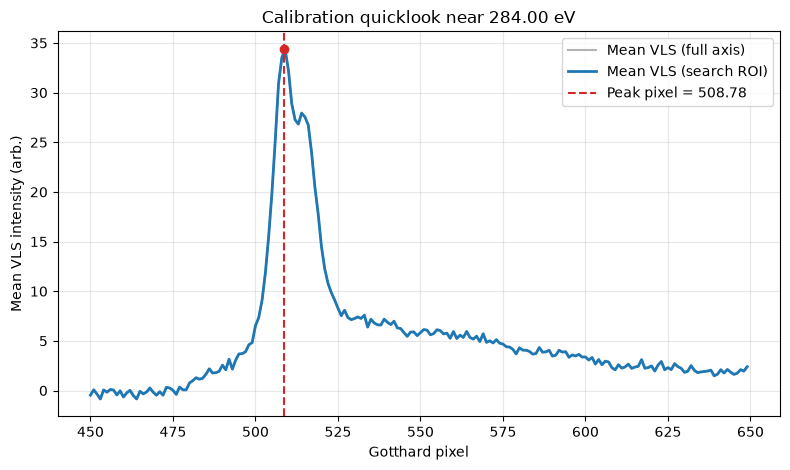

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    cal = sxa.calibration_peak_summary(
        run,
        CALIBRATION_NOMINAL_ENERGY_EV,
        pixel_roi=CALIBRATION_PIXEL_ROI,
    )
    print(f"requested nominal energy : {cal['requested_energy_eV']:.3f} eV")
    print(f"selected nominal energy  : {cal['selected_energy_eV']:.3f} eV")
    print(f"energy index             : {cal['energy_index']}")
    print(f"finite shots used        : {cal['shots_used']}")
    print(f"peak pixel               : {cal['peak_pixel']:.2f}")
    print(f"peak intensity           : {cal['peak_value']:.3g}")
    sxa.plot_calibration_peak(cal)
    plt.show()

### Nominal and shot-resolved energy binning
Counts and filtering summary are retained by the historical result containers.

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **7**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    nominal = sxa.bin_nominal_energy_run(
        run,
        GMD_EDGES,
        vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
        gmd_min_threshold=GMD_MIN_THRESHOLD,
        gmd_max_threshold=GMD_MAX_THRESHOLD,
    )

    shots = sxa.prepare_proxy_shots(
        run,
        vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
        gmd_min_threshold=GMD_MIN_THRESHOLD,
        gmd_max_threshold=GMD_MAX_THRESHOLD,
        center_method=CENTER_METHOD,
        center_half_window=CENTER_HALF_WINDOW,
        center_chunk_size=CENTER_CHUNK_SIZE,
        reject_double_peaks=REJECT_DOUBLE_PEAKS,
        double_peak_kwargs=DOUBLE_PEAK_KWARGS,
    )
    proxy = sxa.bin_proxy_energy(
        shots,
        run.vls_pixels,
        GMD_EDGES,
        pixel_bin_width=PROXY_PIXEL_BIN_WIDTH,
    )
    actual_energy, pixel_map_cfg, pixel_map_cal = sxa.convert_binned_pixels_to_energy(
        proxy,
        PIXEL_MAP_CONFIG,
        PIXEL_MAP_CALIBRATION,
        INVERSE_MAP_RANGE_EV,
        INVERSE_MAP_SAMPLES,
    )

    print(sxa.format_shot_summary(shots, 'filtered'))
    print(f'proxy bins             : {proxy.x.size}')
    print(f'converted energy range : {np.nanmin(actual_energy.x):.3f} .. {np.nanmax(actual_energy.x):.3f} eV')
    print(f'pixel-map magnification: {pixel_map_cfg.magnification}')
    print(f'calibration anchor     : pixel {pixel_map_cal.pixel:.1f} -> {pixel_map_cal.energy_eV:.3f} eV')


filtered: finite=1164240, after peak=573622, after GMD range=556380, high-GMD removed=17242, double rejected=61, after double=556319, after center=556319, final=556319, center=com
proxy bins             : 74
converted energy range : 271.915 .. 285.707 eV
pixel-map magnification: 3.0
calibration anchor     : pixel 524.0 -> 284.200 eV


### Low-GMD spectral lineouts

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **9**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    if LOW_GMD_PLOT_THRESHOLD is not None:
        sxa.plot_low_gmd_spectra(
            run,
            LOW_GMD_PLOT_THRESHOLD,
            vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
            n_examples=N_LOW_GMD_EXAMPLES,
        )
        plt.show()
    else:
        print('LOW_GMD_PLOT_THRESHOLD is None; low-GMD spectrum plot skipped.')


LOW_GMD_PLOT_THRESHOLD is None; low-GMD spectrum plot skipped.


### High-GMD spectral lineouts

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **11**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

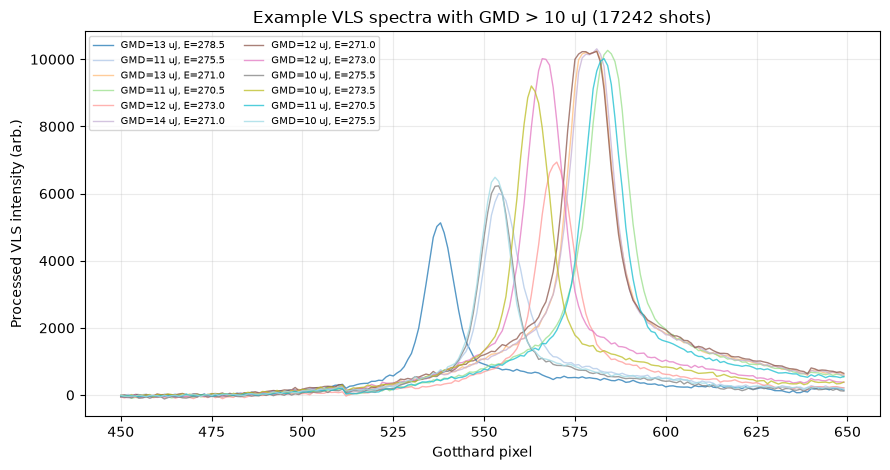

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    if HIGH_GMD_PLOT_THRESHOLD is not None:
        sxa.plot_high_gmd_spectra(
            run,
            HIGH_GMD_PLOT_THRESHOLD,
            vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
            n_examples=N_HIGH_GMD_EXAMPLES,
        )
        plt.show()
    else:
        print('HIGH_GMD_PLOT_THRESHOLD is None; high-GMD spectrum plot skipped.')

### Rejected double-peak examples

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **13**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

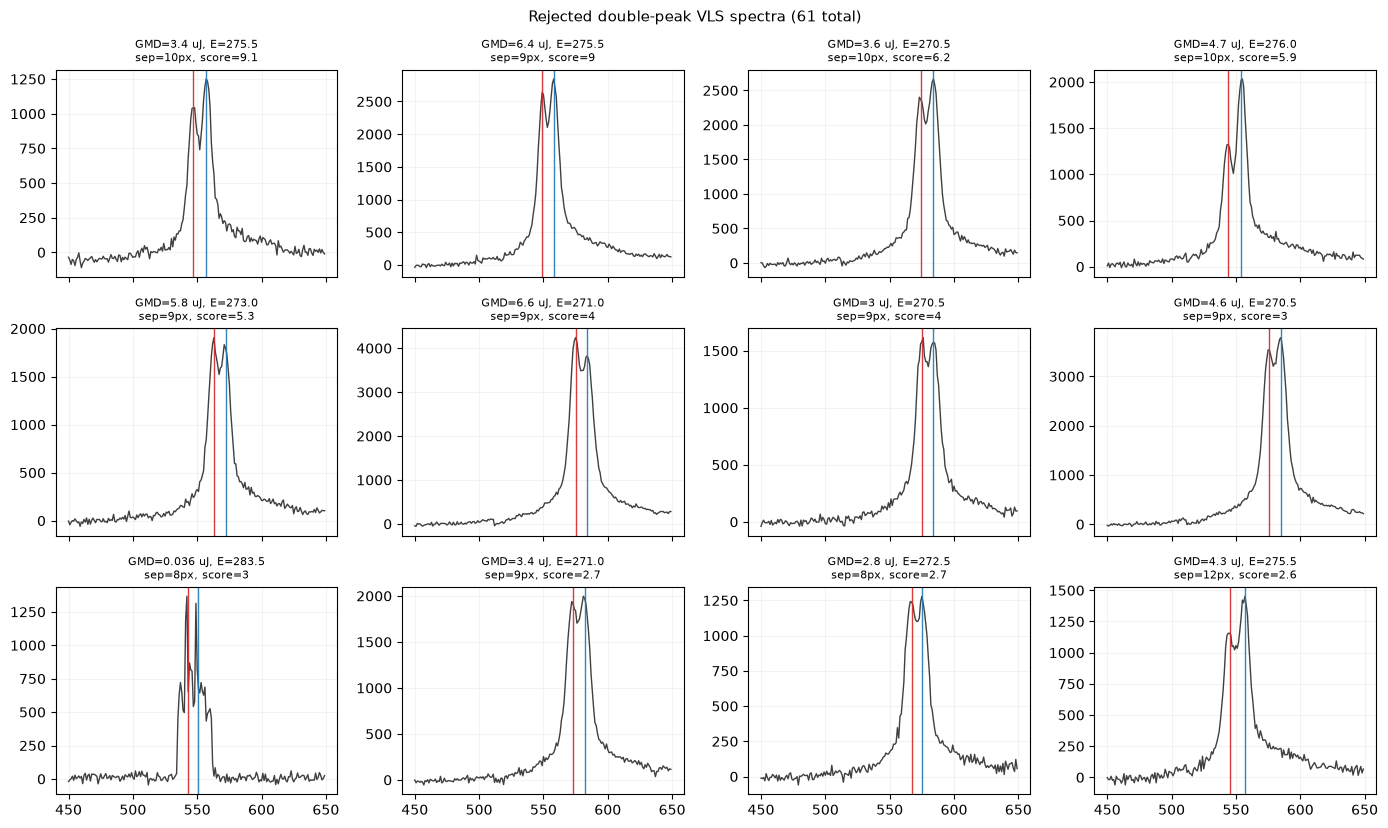

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    sxa.plot_double_peak_examples(
        shots,
        run.vls_pixels,
        n_examples=N_DOUBLE_PEAK_EXAMPLES,
    )
    plt.show()

### Inverse-signal curves by GMD bin

Source: `analysis/notebooks/xas_static_5mmol_simple.ipynb`, cell **15**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

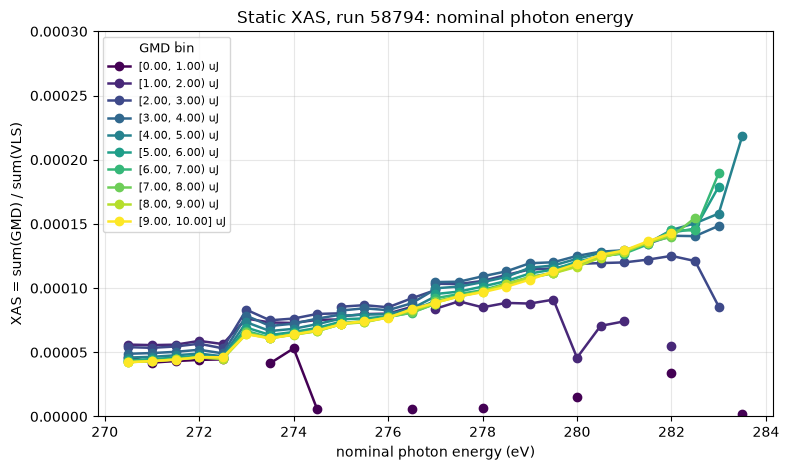

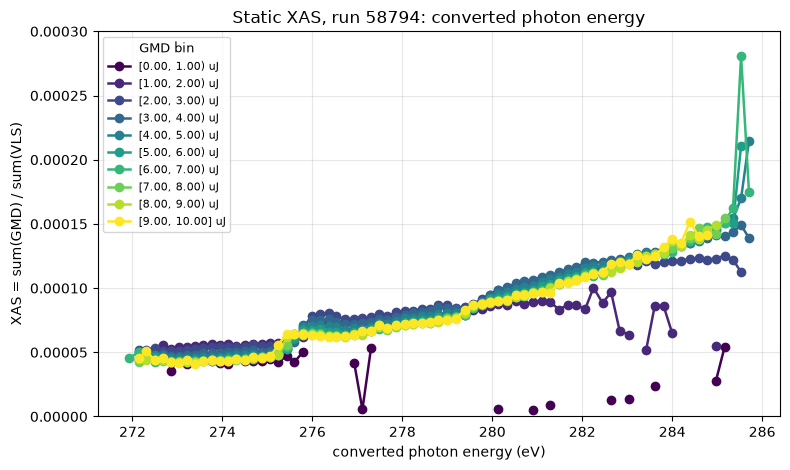

In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    sxa.plot_xas_curves(
        nominal,
        title=f'Static XAS, run {RUN_NO}: nominal photon energy',
        ylim=YLIM,
        marker='o',
    )
    plt.show()

    sxa.plot_xas_curves(
        actual_energy,
        title=f'Static XAS, run {RUN_NO}: converted photon energy',
        ylim=YLIM,
        marker='o',
    )
    plt.show()

## B — Historical reference-based transmission / absorbance

Original `xas_static_5mmol_traditional.ipynb`. Treats 58794 as transmitted and
`reference_frame.h5` as incident intensity. It groups each population independently
by common nominal energies or fixed absolute centre-pixel bins and GMD bins.
`integrated_vls_intensity` first averages finite spectra, then clips negative
mean-spectrum pixels to zero and integrates the selected pixels. The transmission
ratio is `I_trans / I_inc`; `_absorbance_from_binned_intensities` applies
**−log10** of that ratio for positive finite intensities, with no GMD division.
GMD is a selection/binning variable here. Intensity arrays and counts remain in
the returned objects; no new standalone transmission estimator/plot is added.

The historical reference product contains runs 58870/58871, not run 58780.
Its acquisition selections differ (VLS `[2,102)`, GMD `[0,100)`). Reference
compatibility and the common calibration are assumptions to check during
reproduction. Double-peak rejection is **disabled** in this workflow. These
curves are decadic absorbance, distinct from section A and from natural-log OD.

Release section A arrays before the original traditional loader; displayed
notebook outputs remain. Section B resets its own historical parameter dictionary.


In [ ]:
if 'A' in HISTORICAL_SECTIONS:
    import gc
    del run, shots, proxy, actual_energy, nominal, cal
    plt.close('all')
    gc.collect()


Source: `analysis/notebooks/xas_static_5mmol_traditional.ipynb`, cell **2**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'B' in HISTORICAL_SECTIONS:
    ANALYSIS_PARAMS = {
        'TRANSMITTED_RUN_NO': 58794,
        'TRANSMITTED_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'run58794_static_xas.h5',
        'REFERENCE_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'reference_frame.h5',    #Reference I0 spectrum
        'GMD_EDGES': np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]),
        'GMD_MIN_THRESHOLD': None,
        'GMD_MAX_THRESHOLD': 10.0,
        'VLS_INTENSITY_THRESHOLD': 1000,
        'INTENSITY_PIXEL_ROI': None,  # absolute Gotthard pixel range, e.g. (470, 620)
        'CLIP_NEGATIVE_INTENSITY': True,
        'CENTER_METHOD': 'com',
        'CENTER_HALF_WINDOW': 5,
        'CENTER_CHUNK_SIZE': 50000,
        'PROXY_PIXEL_BIN_WIDTH': 1,
        'REJECT_DOUBLE_PEAKS': False,
        'DOUBLE_PEAK_KWARGS': {
            'min_distance_px': 3,
            'max_distance_px': 17,
            'min_prom_sigma': 2.5,
            'min_height_sigma': 2.0,
            'min_rel_peak_height': 0.35,
            'min_second_ratio': 0.05,
            'min_bridge_drop': 0.015,
            'min_split_sigma': 0.75,
        },
        'PIXEL_MAP_CONFIG': {
            'source_to_grating_m': 0.85,
            'grating_to_screen_m': 0.5429,
            'incident_angle_deg': 86.78,
            'groove_density_lines_per_mm': 1200.0,
            'diffraction_order': 1,
            'magnification': 3.0,
            'pixel_pitch_m': 50e-6,
            'axis_sign': 1,
        },
        'PIXEL_MAP_CALIBRATION': {
            'pixel': 524.0,
            'energy_eV': 284.2,
        },
        'INVERSE_MAP_RANGE_EV': (260.0, 290.0),
        'INVERSE_MAP_SAMPLES': 10000,
        'YLIM': None,
    }

    globals().update(ANALYSIS_PARAMS)
    TRANSMITTED_H5 = Path(TRANSMITTED_H5)
    REFERENCE_H5 = Path(REFERENCE_H5)

    print(f'transmitted file      : {TRANSMITTED_H5}')
    print(f'incident file         : {REFERENCE_H5}')
    print(f'gmd edges             : {GMD_EDGES}')
    print(f'gmd min threshold     : {GMD_MIN_THRESHOLD}')
    print(f'gmd max threshold     : {GMD_MAX_THRESHOLD}')
    print(f'vls threshold         : {VLS_INTENSITY_THRESHOLD}')
    print(f'intensity pixel ROI   : {INTENSITY_PIXEL_ROI}')
    print(f'center method         : {CENTER_METHOD}')
    print(f'proxy pixel bin width : {PROXY_PIXEL_BIN_WIDTH}')
    print(f'reject double peaks   : {REJECT_DOUBLE_PEAKS}')


transmitted file      : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5
incident file         : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/reference_frame.h5
gmd edges             : [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
gmd min threshold     : None
gmd max threshold     : 10.0
vls threshold         : 1000
intensity pixel ROI   : None
center method         : com
proxy pixel bin width : 1
reject double peaks   : False


In [ ]:
if 'B' in HISTORICAL_SECTIONS:
    print('Complete traditional-workflow parameters:', ANALYSIS_PARAMS)
    inspect_processed_metadata(TRANSMITTED_H5)
    inspect_processed_metadata(REFERENCE_H5)


Complete traditional-workflow parameters: {'TRANSMITTED_RUN_NO': 58794, 'TRANSMITTED_H5': PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), 'REFERENCE_H5': PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/reference_frame.h5'), 'GMD_EDGES': array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]), 'GMD_MIN_THRESHOLD': None, 'GMD_MAX_THRESHOLD': 10.0, 'VLS_INTENSITY_THRESHOLD': 1000, 'INTENSITY_PIXEL_ROI': None, 'CLIP_NEGATIVE_INTENSITY': True, 'CENTER_METHOD': 'com', 'CENTER_HALF_WINDOW': 5, 'CENTER_CHUNK_SIZE': 50000, 'PROXY_PIXEL_BIN_WIDTH': 1, 'REJECT_DOUBLE_PEAKS': False, 'DOUBLE_PEAK_KWARGS': {'min_distance_px': 3, 'max_distance_px': 17, 'min_prom_sigma': 2.5, 'min_height_sigma': 2.0, 'min_rel_peak_height': 0.35, 'min_second_ratio': 0.05, 'min_bridge_drop': 0.015, 'min_split_sigma': 0.75}, 'PIXEL_MAP_CONFIG': {'source_to_grating_m': 0.85, 'grating_to_screen_m': 0.5429, 'incident_angle_deg': 86.78, 'gro

Source: `analysis/notebooks/xas_static_5mmol_traditional.ipynb`, cell **3**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'B' in HISTORICAL_SECTIONS:
    if not TRANSMITTED_H5.exists():
        raise FileNotFoundError(f'Missing transmitted static-XAS file: {TRANSMITTED_H5}')
    if not REFERENCE_H5.exists():
        raise FileNotFoundError(f'Missing reference-frame static-XAS file: {REFERENCE_H5}')

    trans_run = sxa.load_static_xas_run(TRANSMITTED_H5)
    ref_run = sxa.load_static_xas_run(REFERENCE_H5)

    print(f"transmitted run       : {trans_run.attrs.get('run_no')}")
    print(f"transmitted shape     : {trans_run.vls.shape}")
    print(f"transmitted E range   : {np.nanmin(trans_run.nominal_energies):.2f} .. {np.nanmax(trans_run.nominal_energies):.2f} eV")
    print(f"transmitted shots     : {trans_run.stored_shots}")
    print(f"reference run         : {ref_run.attrs.get('run_no')}")
    print(f"reference shape       : {ref_run.vls.shape}")
    print(f"reference E range     : {np.nanmin(ref_run.nominal_energies):.2f} .. {np.nanmax(ref_run.nominal_energies):.2f} eV")
    print(f"reference shots       : {ref_run.stored_shots}")


transmitted run       : 58794
transmitted shape     : (31, 102720, 200)
transmitted E range   : 270.00 .. 284.00 eV
transmitted shots     : 1164240
reference run         : [58870 58871]
reference shape       : (41, 72500, 200)
reference E range     : 270.00 .. 300.00 eV
reference shots       : 2281200


Source: `analysis/notebooks/xas_static_5mmol_traditional.ipynb`, cell **4**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

In [ ]:
if 'B' in HISTORICAL_SECTIONS:
    nominal_abs_gmd = sxa.build_nominal_gmd_binned_absorbance_curve(
        trans_run,
        ref_run,
        GMD_EDGES,
        vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
        gmd_min_threshold=GMD_MIN_THRESHOLD,
        gmd_max_threshold=GMD_MAX_THRESHOLD,
        reject_double_peaks=REJECT_DOUBLE_PEAKS,
        double_peak_kwargs=DOUBLE_PEAK_KWARGS,
        intensity_pixel_roi=INTENSITY_PIXEL_ROI,
        clip_negative=CLIP_NEGATIVE_INTENSITY,
    )

    actual_abs_gmd = sxa.build_actual_gmd_binned_absorbance_curve(
        trans_run,
        ref_run,
        GMD_EDGES,
        PIXEL_MAP_CONFIG,
        PIXEL_MAP_CALIBRATION,
        INVERSE_MAP_RANGE_EV,
        n_samples=INVERSE_MAP_SAMPLES,
        pixel_bin_width=PROXY_PIXEL_BIN_WIDTH,
        vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
        gmd_min_threshold=GMD_MIN_THRESHOLD,
        gmd_max_threshold=GMD_MAX_THRESHOLD,
        center_method=CENTER_METHOD,
        center_half_window=CENTER_HALF_WINDOW,
        center_chunk_size=CENTER_CHUNK_SIZE,
        reject_double_peaks=REJECT_DOUBLE_PEAKS,
        double_peak_kwargs=DOUBLE_PEAK_KWARGS,
        intensity_pixel_roi=INTENSITY_PIXEL_ROI,
        clip_negative=CLIP_NEGATIVE_INTENSITY,
    )

    print(f"nominal common bins   : {nominal_abs_gmd.x.size}")
    print(f"actual common bins    : {actual_abs_gmd.x.size}")
    print(f"nominal trans shots   : {int(np.sum(nominal_abs_gmd.n_trans))}")
    print(f"nominal ref shots     : {int(np.sum(nominal_abs_gmd.n_incident))}")
    print(f"actual trans shots    : {int(np.sum(actual_abs_gmd.n_trans))}")
    print(f"actual ref shots      : {int(np.sum(actual_abs_gmd.n_incident))}")


nominal common bins   : 21
actual common bins    : 65
nominal trans shots   : 484700
nominal ref shots     : 424954
actual trans shots    : 539044
actual ref shots      : 394795


Source: `analysis/notebooks/xas_static_5mmol_traditional.ipynb`, cell **5**, local `main` @ `e3dfa92bf5669a882d67dc5e772e915e4638d645`. Copied verbatim.

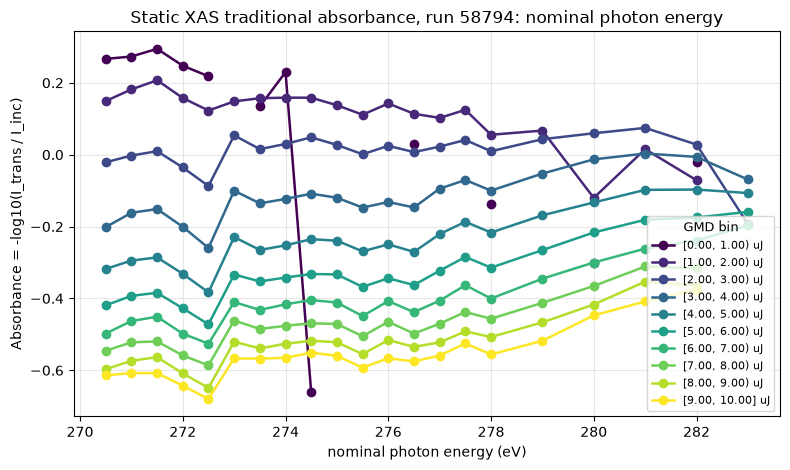

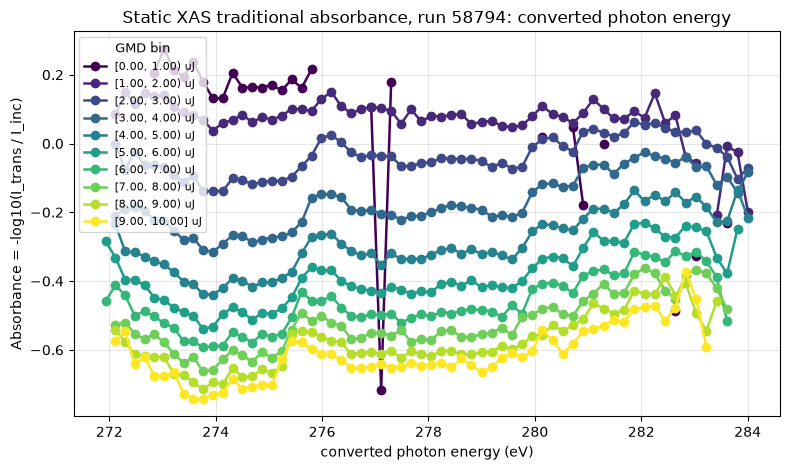

In [ ]:
if 'B' in HISTORICAL_SECTIONS:
    sxa.plot_gmd_binned_absorbance_curves(
        nominal_abs_gmd,
        title=f'Static XAS traditional absorbance, run {TRANSMITTED_RUN_NO}: nominal photon energy',
        ylim=YLIM,
    )
    plt.show()

    sxa.plot_gmd_binned_absorbance_curves(
        actual_abs_gmd,
        title=f'Static XAS traditional absorbance, run {TRANSMITTED_RUN_NO}: converted photon energy',
        ylim=YLIM,
    )
    plt.show()


## Reproduction status

Compilation/static validation only. No results or plots in this notebook have
been executed or compared. Keep the two workflows and their filtering populations
distinct. Review memory and current product provenance before execution. This
notebook does not regenerate HDF5 products, correct energy labels, refit calibration
or adapt the historical parameters to the new beamtime.


## Updated-source alternatives — explicit opt-in (Task A)

Sections A/B above, including saved outputs, remain unchanged. Their stale compilation-status
text is retained as part of the historical record; numerical reproduction is documented in
`validation/stage1d_20261020/VALIDATION_REPORT.md` (exact pinned-source replay, not equality
to all archived outputs). The alternatives below are **compiled only; not numerically validated**.
Sources: updated main `f940ee05ddc9fbbd2b0faa95cc25085608792323`; baseline `e3dfa92…`.
All source cell indices are zero-based including Markdown. Run setup cell 1, then the desired
optional section; A/B need not be re-executed. Do not run all workflows concurrently.
No section generates HDF5 or repairs upstream frame pairing/backgrounds. New methods do not
validate the independent +10/+2 offsets. Native GMD units remain arbitrary; fitted scaling
is not an absolute µJ calibration. Photon-energy coordinates concern shot spectral centres,
not a full spectrum in counts/eV. Source definitions and adaptations: `historical_sources_03_review.json`.


In [ ]:
if HISTORICAL_SECTIONS & set('CDEFG'):
    from historical import static_xas_comparison as xc
    from historical import review_diagnostics as review
    REVIEW_COMMIT = 'f940ee05ddc9fbbd2b0faa95cc25085608792323'
    REVIEW_SAMPLE_H5 = path_config.XAS_STATIC_DIR / 'run58794_static_xas.h5'
    REVIEW_OLD_REFERENCE_H5 = path_config.XAS_STATIC_DIR / 'reference_frame.h5'
    REVIEW_MEASURED_REFERENCE_H5 = path_config.XAS_STATIC_DIR / 'run58780_static_xas.h5'
    # Future generated products must be project-local. Nothing creates this directory here.
    REVIEW_GOOD_DIR = (PROJECT_ROOT / 'products' / 'static_xas_good').resolve()
    if PROJECT_ROOT.resolve() not in REVIEW_GOOD_DIR.parents:
        raise ValueError('Good-product destination must remain inside FLASH_Gotthard')
    print('Updated source:', REVIEW_COMMIT)
    print('Sample / historical reference / new reference:', REVIEW_SAMPLE_H5, REVIEW_OLD_REFERENCE_H5, REVIEW_MEASURED_REFERENCE_H5)
    print('Future good-product location:', REVIEW_GOOD_DIR)


Updated source: f940ee05ddc9fbbd2b0faa95cc25085608792323
Sample / historical reference / new reference: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5 /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/reference_frame.h5 /asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58780_static_xas.h5
Future good-product location: /home/mmanresa/FLASH_Gotthard/products/static_xas_good


## C — Isolate root versus mapped hall GMD

New orchestration around the **unchanged baseline** `static_xas_analysis.py` functions used
in A/B (original simple cells 2/7/15 and traditional cells 2/4/5). Updated source
`static_xas_analysis.py::read_hall_gmd_array/load_static_xas_run` motivates the alternative:
`/ml/gmd_hall_channels[...,0]` is mapped intensity, channel-last in these processed files.
No fallback is allowed. Same recorded `(section, shot)` rows, VLS, energy assignments,
filters, geometry, bin edges, clipping and references are used in both versions.

Set the three execution flags independently. The full simple/reference replays can reach
approximately 13/21 GiB RSS (prior validation); existing detector arrays are shared when
available, and only compact replay results are retained. The streamed population audit
uses the nominal-branch cuts only, before double-peak/centre filtering. Its mean-of-shot
`sum_pixels(VLS)/GMD` diagnostic is **not** the ratio-of-sums XAS observable.


In [ ]:
if HISTORICAL_SECTIONS & set('CDEFG'):
    GMD_SIMPLE_PARAMS = {
        'RUN_NO': 58794,
        'INPUT_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'run58794_static_xas.h5',
        #'GMD_EDGES': np.array([0.0, 1.6, 3.2, 6.4, 12.8]),
        'GMD_EDGES': np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]),
        'GMD_MIN_THRESHOLD': None,  # set to a number to reject GMD below this value
        'GMD_MAX_THRESHOLD': 10.0,  # set to None to disable the high-GMD filter
        'VLS_INTENSITY_THRESHOLD': 1000,
        'CENTER_METHOD': 'com',  # 'com', 'peak', 'smooth_peak'/'peak_smooth', or 'gaussian_logfit'
        'CENTER_HALF_WINDOW': 5,  # non-peak centers use strongest-peak +/- this many pixels
        'CENTER_CHUNK_SIZE': 50000,
        'PROXY_PIXEL_BIN_WIDTH': 1,  # pixel-proxy bin width, in Gotthard pixels
        'REJECT_DOUBLE_PEAKS': True,
        'DOUBLE_PEAK_KWARGS': {
            'min_distance_px': 3,
            'max_distance_px': 17,
            'min_prom_sigma': 2.5,
            'min_height_sigma': 2.0,
            'min_rel_peak_height': 0.35,
            'min_second_ratio': 0.05,
            'min_bridge_drop': 0.015,
            'min_split_sigma': 0.75,
        },
        'N_DOUBLE_PEAK_EXAMPLES': 12,
        'N_LOW_GMD_EXAMPLES': 12,
        'N_HIGH_GMD_EXAMPLES': 12,
        'CALIBRATION_NOMINAL_ENERGY_EV': 284.0,
        'CALIBRATION_PIXEL_ROI': None,  # absolute Gotthard pixel range, e.g. (510, 540)
        'PIXEL_MAP_CONFIG': {
            'source_to_grating_m': 0.85,
            'grating_to_screen_m': 0.5429,
            'incident_angle_deg': 86.78,
            'groove_density_lines_per_mm': 1200.0,
            'diffraction_order': 1,
            'magnification': 3.0,
            'pixel_pitch_m': 50e-6,
            'axis_sign': 1,
        },
        'PIXEL_MAP_CALIBRATION': {
            'pixel': 524.0,
            'energy_eV': 284.2,
        },
        'INVERSE_MAP_RANGE_EV': (260.0, 290.0),
        'INVERSE_MAP_SAMPLES': 10000,
        'YLIM': (0, 3.0e-4),
    }


In [ ]:
if HISTORICAL_SECTIONS & set('CDEFG'):
    GMD_REFERENCE_PARAMS = {
        'TRANSMITTED_RUN_NO': 58794,
        'TRANSMITTED_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'run58794_static_xas.h5',
        'REFERENCE_H5': Path(path_config.COMBINED_DIR).parent / 'xas_static' / 'reference_frame.h5',    #Reference I0 spectrum
        'GMD_EDGES': np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]),
        'GMD_MIN_THRESHOLD': None,
        'GMD_MAX_THRESHOLD': 10.0,
        'VLS_INTENSITY_THRESHOLD': 1000,
        'INTENSITY_PIXEL_ROI': None,  # absolute Gotthard pixel range, e.g. (470, 620)
        'CLIP_NEGATIVE_INTENSITY': True,
        'CENTER_METHOD': 'com',
        'CENTER_HALF_WINDOW': 5,
        'CENTER_CHUNK_SIZE': 50000,
        'PROXY_PIXEL_BIN_WIDTH': 1,
        'REJECT_DOUBLE_PEAKS': False,
        'DOUBLE_PEAK_KWARGS': {
            'min_distance_px': 3,
            'max_distance_px': 17,
            'min_prom_sigma': 2.5,
            'min_height_sigma': 2.0,
            'min_rel_peak_height': 0.35,
            'min_second_ratio': 0.05,
            'min_bridge_drop': 0.015,
            'min_split_sigma': 0.75,
        },
        'PIXEL_MAP_CONFIG': {
            'source_to_grating_m': 0.85,
            'grating_to_screen_m': 0.5429,
            'incident_angle_deg': 86.78,
            'groove_density_lines_per_mm': 1200.0,
            'diffraction_order': 1,
            'magnification': 3.0,
            'pixel_pitch_m': 50e-6,
            'axis_sign': 1,
        },
        'PIXEL_MAP_CALIBRATION': {
            'pixel': 524.0,
            'energy_eV': 284.2,
        },
        'INVERSE_MAP_RANGE_EV': (260.0, 290.0),
        'INVERSE_MAP_SAMPLES': 10000,
        'YLIM': None,
    }


In [ ]:
if 'C' in HISTORICAL_SECTIONS:
    GMD_AUDIT_ENABLED = True
    GMD_SIMPLE_REPLAY_ENABLED = False
    GMD_REFERENCE_REPLAY_ENABLED = False
    GMD_AUDIT_CHUNK_SIZE = 2000
    GMD_AUDIT_SECTION = 4       # stored section index, not a requested energy label
    GMD_AUDIT_BIN = 3
    # Change paths here, keeping both sources on exactly the same file/population.
    GMD_SIMPLE_PARAMS['INPUT_H5'] = REVIEW_SAMPLE_H5
    GMD_REFERENCE_PARAMS['TRANSMITTED_H5'] = REVIEW_SAMPLE_H5
    GMD_REFERENCE_PARAMS['REFERENCE_H5'] = REVIEW_OLD_REFERENCE_H5
    # Separate state; never change original run/trans_run/ref_run or ANALYSIS_PARAMS.
    gmd_population_results = {}
    gmd_simple_results = {}
    gmd_reference_results = {}


{'path': '/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5', 'datasets': {'vls': {'shape': (31, 102720, 200), 'dtype': 'float64'}, 'gmd': {'shape': (31, 102720), 'dtype': 'float64'}, 'n_shots': {'shape': (31,), 'dtype': 'int64'}, 'nominal_energies': {'shape': (31,), 'dtype': 'float64'}, 'vls_pixels': {'shape': (200,), 'dtype': 'int64'}, 'ml/gmd_hall_channels': {'shape': (31, 102720, 8), 'dtype': 'float32'}, 'noise/vls_bg_sigma_global': {'shape': (200,), 'dtype': 'float64'}, 'ml/qc_ok': {'shape': (31, 102720), 'dtype': 'bool'}, 'ml/train_id': {'shape': (31, 102720), 'dtype': 'int64'}, 'ml/vls_bunch_index': {'shape': (31, 102720), 'dtype': 'int16'}, 'ml/gmd_bunch_index': {'shape': (31, 102720), 'dtype': 'int16'}}, 'vls_GiB': 4.745006561279297, 'recorded_shots': 1164240, 'attrs': {'bg_bunch_range': array([ 50, 100]), 'config': np.int64(2), 'config_path': 'analysis/configs/xas_static/5mmol_gly_03June_night.py', 'first_section_state': 'open', 'gmd_bunch_

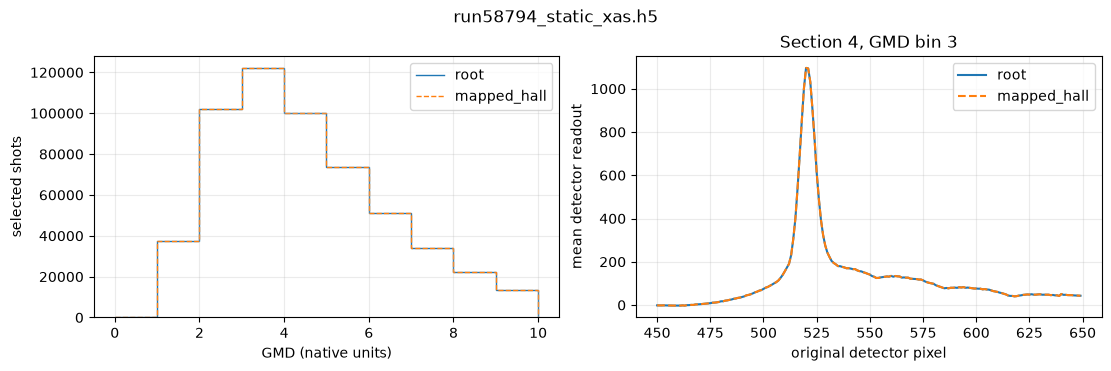

{'path': '/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/reference_frame.h5', 'datasets': {'vls': {'shape': (41, 72500, 200), 'dtype': 'float64'}, 'gmd': {'shape': (41, 72500), 'dtype': 'float64'}, 'n_shots': {'shape': (41,), 'dtype': 'int64'}, 'nominal_energies': {'shape': (41,), 'dtype': 'float64'}, 'vls_pixels': {'shape': (200,), 'dtype': 'int64'}, 'ml/gmd_hall_channels': {'shape': (41, 72500, 8), 'dtype': 'float32'}, 'ml/qc_ok': {'shape': (41, 72500), 'dtype': 'bool'}, 'ml/train_id': {'shape': (41, 72500), 'dtype': 'int64'}, 'ml/vls_bunch_index': {'shape': (41, 72500), 'dtype': 'int16'}, 'ml/gmd_bunch_index': {'shape': (41, 72500), 'dtype': 'int16'}}, 'vls_GiB': 4.429370164871216, 'recorded_shots': 2281200, 'attrs': {'bg_bunch_range': array([102, 110]), 'config': np.int64(2), 'config_path': 'analysis/configs/xas_static/reference_frame.py', 'first_section_state': 'open', 'gmd_bunch_start': np.int64(0), 'gmd_signal_bunch_range': array([  0, 100]), 'gmd_tunnel_index_pa

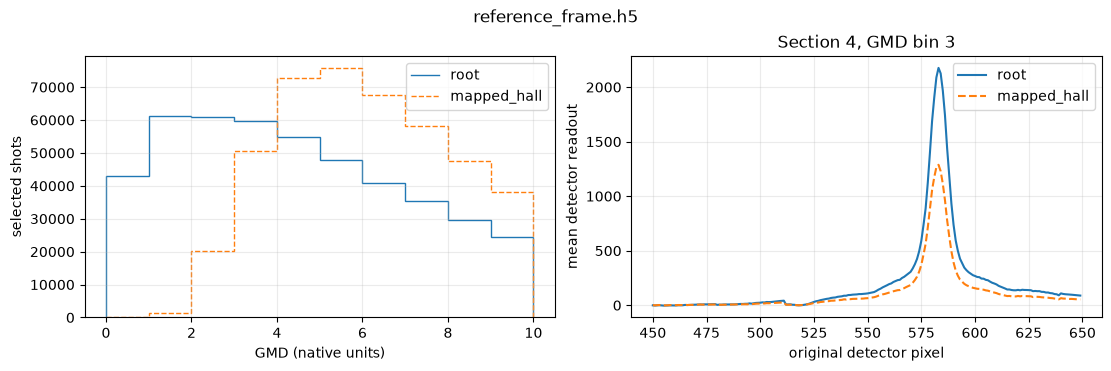

In [ ]:
if 'C' in HISTORICAL_SECTIONS:
    if GMD_AUDIT_ENABLED:
        for audit_path in (REVIEW_SAMPLE_H5, REVIEW_OLD_REFERENCE_H5):
            print(xc.processed_schema(audit_path))
            # Small identity/association sample; configured identity indices are not timing proof.
            print(review.gmd_provenance(audit_path, max_sections=3, shots_per_section=100))
            audit = xc.population_audit(audit_path, GMD_SIMPLE_PARAMS, GMD_AUDIT_CHUNK_SIZE)
            gmd_population_results[str(audit_path)] = audit
            for source in ('root', 'mapped_hall'):
                print(audit_path.name, source, {k:audit[source][k] for k in ('finite','selected','mean_shot_T_over_G')})
            print('Row / finite-coverage / selection disagreements:', audit['row_disagreement'], audit['finite_coverage_disagreement'], audit['selection_disagreement'])
            fig, axes = plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
            for source,style in (('root','-'),('mapped_hall','--')):
                r = audit[source]
                axes[0].stairs(r['histogram'],GMD_SIMPLE_PARAMS['GMD_EDGES'],label=source,linestyle=style)
                axes[1].plot(audit['pixels'],r['mean_spectrum'][GMD_AUDIT_SECTION,GMD_AUDIT_BIN],style,label=source)
                print(source, 'displayed spectrum population:', r['bin_counts'][GMD_AUDIT_SECTION,GMD_AUDIT_BIN])
            axes[0].set(xlabel='GMD (native units)',ylabel='selected shots')
            axes[1].set(xlabel='original detector pixel',ylabel='mean detector readout',title=f'Section {GMD_AUDIT_SECTION}, GMD bin {GMD_AUDIT_BIN}')
            for ax in axes: ax.legend(); ax.grid(alpha=.25)
            fig.suptitle(audit_path.name); plt.show()
    else:
        print('Root/mapped streamed population audit disabled.')


In [ ]:
if 'C' in HISTORICAL_SECTIONS:
    if GMD_SIMPLE_REPLAY_ENABLED:
        reuse_sample = globals().get('trans_run')
        if reuse_sample is not None and Path(reuse_sample.path).resolve() != Path(GMD_SIMPLE_PARAMS['INPUT_H5']).resolve():
            reuse_sample = None
        comparison_sample = xc.with_gmd(GMD_SIMPLE_PARAMS['INPUT_H5'], 'root', reuse_sample)
        for source in ('root','mapped_hall'):
            selected_run = xc.with_gmd(GMD_SIMPLE_PARAMS['INPUT_H5'], source, comparison_sample)
            gmd_simple_results[source] = xc.simple_replay(selected_run, GMD_SIMPLE_PARAMS)
            print(source, gmd_simple_results[source]['shot_summary'])
        for axis in ('nominal','converted'):
            diff = xc.compare_curves(gmd_simple_results['root'][axis],gmd_simple_results['mapped_hall'][axis],'xas')
            print(axis, {k:v for k,v in diff.items() if k in ('both_finite','finite_coverage_disagreement','max_abs_difference','root_only_x','mapped_only_x')})
            fig, ax = plt.subplots(figsize=(8,4))
            for source,style in (('root','-'),('mapped_hall','--')):
                curve=gmd_simple_results[source][axis]
                for ig in range(curve.xas.shape[1]):
                    ax.plot(curve.x,curve.xas[:,ig],style,color=plt.cm.inferno((ig+.5)/curve.xas.shape[1]),label=source if ig==0 else None)
                print(source, axis, 'counts:',curve.n_per_bin)
            ax.set(xlabel=f'{axis} photon energy (eV)',ylabel='sum(GMD) / sum(VLS)',title='GMD-source comparison; all other choices fixed')
            ax.legend();ax.grid(alpha=.25);plt.show()
        del selected_run, comparison_sample, reuse_sample
    else:
        print('Full root/mapped inverse-signal replay disabled.')


Full root/mapped inverse-signal replay disabled.


In [ ]:
if 'C' in HISTORICAL_SECTIONS:
    if GMD_REFERENCE_REPLAY_ENABLED:
        p=GMD_REFERENCE_PARAMS
        reuse_sample=globals().get('trans_run');reuse_reference=globals().get('ref_run')
        if reuse_sample is not None and Path(reuse_sample.path).resolve()!=Path(p['TRANSMITTED_H5']).resolve(): reuse_sample=None
        if reuse_reference is not None and Path(reuse_reference.path).resolve()!=Path(p['REFERENCE_H5']).resolve(): reuse_reference=None
        comparison_sample=xc.with_gmd(p['TRANSMITTED_H5'],'root',reuse_sample)
        comparison_reference=xc.with_gmd(p['REFERENCE_H5'],'root',reuse_reference)
        for source in ('root','mapped_hall'):
            sample_source=xc.with_gmd(p['TRANSMITTED_H5'],source,comparison_sample)
            reference_source=xc.with_gmd(p['REFERENCE_H5'],source,comparison_reference)
            gmd_reference_results[source]=xc.reference_replay(sample_source,reference_source,p)
        for axis in ('nominal','converted'):
            root_curve=gmd_reference_results['root'][axis];mapped_curve=gmd_reference_results['mapped_hall'][axis]
            difference=xc.compare_curves(root_curve,mapped_curve,'absorbance')
            print(axis, 'max |mapped-root|:',difference['max_abs_difference'],'common finite cells:',difference['both_finite'],
                  'finite-coverage disagreement:',difference['finite_coverage_disagreement'],
                  'root/mapped-only energies:',difference['root_only_x'],difference['mapped_only_x'])
            for source in ('root','mapped_hall'):
                curve=gmd_reference_results[source][axis]
                print(source,axis,'sample/reference counts:',curve.n_trans,curve.n_incident)
                sxa.plot_gmd_binned_absorbance_curves(curve,title=f'{source} GMD only — {axis} energy',ylim=p['YLIM'])
                xc.relabel_native_gmd(plt.gcf())  # alternative displays native units; original B unchanged
                plt.show()
        del sample_source,reference_source,comparison_sample,comparison_reference,reuse_sample,reuse_reference
    else:
        print('Full root/mapped historical-reference replay disabled.')


Full root/mapped historical-reference replay disabled.


## D — New selection layer and accepted-shot products

Source: updated `xas_static/process_processed_data_xas_static.ipynb` cells 1–4;
`static_xas_process_good.py::basic_qc_mask/peak_metrics/fit_vls_pixel_energy_calibration`.
Only safe definitions already extracted in `historical/review_calibration.py` are used.
**The processing script and writer are neither imported nor called.**

Basic selection requires finite VLS/GMD and optionally `/ml/qc_ok`; peak SNR is prominence
above side-percentile background divided by stored raw-noise sigma near the peak.
The local COM subtracts its own fixed 20th-percentile baseline and clips weights at zero.
These are peak metrics, not another subtraction of the stored detector spectrum.
The preview below compares peak>1000 and SNR>5 populations on the same bounded recorded rows;
it does not reproduce the full good workflow or double-peak rejection. The empirical fit
uses section median accepted centres, sqrt(N) weights and stored section energies
(prefer `/section_energy_raw_eV`). See notebook02 for the geometry/empirical comparison.
Good products retain source-shot indices, QC, fitted intercepts and calibrated shot centres.
Their existence does not establish correct upstream pulse association or background windows.


In [ ]:
if 'D' in HISTORICAL_SECTIONS:
    from historical import review_calibration as rc
    NEW_QC_PREVIEW_ENABLED = False
    NEW_QC_INPUT = REVIEW_SAMPLE_H5
    NEW_QC_SHOTS_PER_SECTION = 64
    NEW_QC_SECTIONS = None       # None = all stored sections; or explicit section-index list
    NEW_QC_HISTORICAL_PEAK_THRESHOLD = 1000.0
    NEW_QC_CONFIG = rc.ProcessGoodConfig(
        input_h5=NEW_QC_INPUT,
        output_h5=REVIEW_GOOD_DIR/'run58794_good_static_xas.h5',
        gmd_source='hall', use_ml_qc_ok=True, chunk_size=20000,
        energy_group_decimals=3, proxy_pixel_bin_width=1,
        energy_calibration_poly_order=1, energy_calibration_min_sections=4,
        peak_snr_threshold=5.0, prominence_inner_px=5, prominence_outer_px=20,
        prominence_baseline_percentile=20.0, sigma_half_window_px=5,
        center_half_window_px=5, min_side_pixels=5,
    )
    if PROJECT_ROOT.resolve() not in Path(NEW_QC_CONFIG.output_h5).resolve().parents:
        raise ValueError('Future output path outside project')
    print(NEW_QC_CONFIG)
    new_qc_preview = []


ProcessGoodConfig(input_h5=PosixPath('/asap3/flash/gpfs/fl24/2026/data/11022188/processed/xas_static/run58794_static_xas.h5'), output_h5=PosixPath('/home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58794_good_static_xas.h5'), use_ml_qc_ok=True, chunk_size=20000, energy_group_decimals=3, proxy_pixel_bin_width=1, energy_calibration_poly_order=1, energy_calibration_min_sections=4, peak_snr_threshold=5.0, prominence_inner_px=5, prominence_outer_px=20, prominence_baseline_percentile=20.0, sigma_half_window_px=5, center_half_window_px=5, min_side_pixels=5, gmd_source='hall')


In [ ]:
if 'D' in HISTORICAL_SECTIONS:
    if NEW_QC_PREVIEW_ENABLED:
        print(xc.processed_schema(NEW_QC_INPUT))
        info = rc.read_static_info(NEW_QC_INPUT,group_decimals=NEW_QC_CONFIG.energy_group_decimals)
        if NEW_QC_CONFIG.gmd_source not in ('hall','tunnel'): raise ValueError('Unknown GMD source')
        key = 'ml/gmd_hall_channels' if NEW_QC_CONFIG.gmd_source=='hall' else 'ml/gmd_tunnel_channels'
        if not isinstance(NEW_QC_SHOTS_PER_SECTION,int) or NEW_QC_SHOTS_PER_SECTION<1: raise ValueError('Positive preview limit required')
        sections = list(range(info.n_energy)) if NEW_QC_SECTIONS is None else list(NEW_QC_SECTIONS)
        with h5py.File(NEW_QC_INPUT,'r') as f:
            if key not in f: raise KeyError(f'Missing requested {key}; no fallback')
            if f[key].shape != (info.n_energy,info.max_shots,8): raise ValueError('Mapped GMD axes differ')
            if info.sigma_raw.shape != (info.n_pixels,): raise ValueError('Stored noise/pixel axes differ')
            for ie in sections:
                if not isinstance(ie,(int,np.integer)) or ie<0 or ie>=info.n_energy: raise ValueError('Invalid section index')
                count=int(info.n_shots[ie])
                if count<=0: continue
                idx=np.unique(np.linspace(0,count-1,min(count,NEW_QC_SHOTS_PER_SECTION),dtype=int))
                v=f['vls'][ie,idx,:];g=f[key][ie,idx,0]
                qc=f['ml/qc_ok'][ie,idx].astype(bool) if 'ml/qc_ok' in f else np.ones(idx.size,bool)
                basic=rc.basic_qc_mask(v,g,qc,NEW_QC_CONFIG)
                peaks=rc.peak_metrics(v,info.sigma_raw,info.vls_pixels,NEW_QC_CONFIG)
                snr_keep=basic & np.isfinite(peaks['center_pixel']) & (peaks['peak_snr']>NEW_QC_CONFIG.peak_snr_threshold)
                historical_peak=np.isfinite(g)&np.all(np.isfinite(v),axis=1)&(np.max(v,axis=1)>=NEW_QC_HISTORICAL_PEAK_THRESHOLD)
                new_qc_preview.append(dict(section=ie,source_shot_index=idx,basic=basic,historical_peak=historical_peak,snr_keep=snr_keep,peak_metrics=peaks))
                print(ie,'sampled/basic/historical-peak/SNR:',len(idx),int(basic.sum()),int(historical_peak.sum()),int(snr_keep.sum()))
        print('BOUNDED preview only; no full calibration fit, correction or good product generated.')
    else:
        print('New selection preview disabled. No detector values read by this section.')


New selection preview disabled. No detector values read by this section.


## E — Logarithmic GMD proxy using existing processed data (geometry)

Source: updated `xas_static_5mmol_gmd_difference_xas.ipynb` cells 0–4 and
`static_xas_thesis_core_xas.py::compute_thesis_core_xas`. This can use existing run58794
without a good file. It reads mapped hall GMD, keeps finite shots with peak>=1000 and
GMD cuts, fits `T=a(E_nominal)+b(E_nominal)G`, then optionally uses `T*=T−a`.
Unlike A, it computes a logarithm; it does not add SNR or double-peak rejection.
Nominal per-section fits and geometrical shot-centre energy are retained exactly.

For `reference_window`, `c=Σ(G T*)/ΣG²` over the explicit **nominal 272–273 eV window**;
`Q=log10[ΣG/Σ(T*/c)]`. `none` and `global_slope` are distinct scaling alternatives.
Without empirical scaling, the log retains an arbitrary detector/GMD scale. Fitted
intercepts are response-model assumptions, not a measured dark or incident spectrum.
`nominal_raw`/`nominal_corrected` share the same fitted scale: compare them to isolate
intercept effects. Refit with a different mode only as a separately recorded experiment.


Selected populations: {'recorded': array([ 79200,  35160,  39000,  35040,  35790,  39720,  35580,  33240,
        38130,  45570,  38700,  34290,  35010,  35700,  17040,  17400,
        34020,  37710,  34920,   9930,  22530,  37260,  35520,  33210,
        33390,  39030,  35610,  34140,  42720,  36960, 102720]), 'finite': array([ 79200,  35160,  39000,  35040,  35790,  39720,  35580,  33240,
        38130,  45570,  38700,  34290,  35010,  35700,  17040,  17400,
        34020,  37710,  34920,   9930,  22530,  37260,  35520,  33210,
        33390,  39030,  35610,  34140,  42720,  36960, 102720]), 'peak_rejected': array([ 79200,  35158,  38789,  33224,  30787,  29250,  22983,  18766,
        20032,  20957,  15695,  13471,  10340,   8988,   4796,   4343,
        17685,  12365,   4598,   1333,   2137,   6668,   7295,   5114,
         5055,  16913,   6814,   7379,   3991,   3772, 102720]), 'gmd_rejected': array([   0,    0,    0,    0,    2,    9,   32,   95,   85,  209,  353,
        201,  6

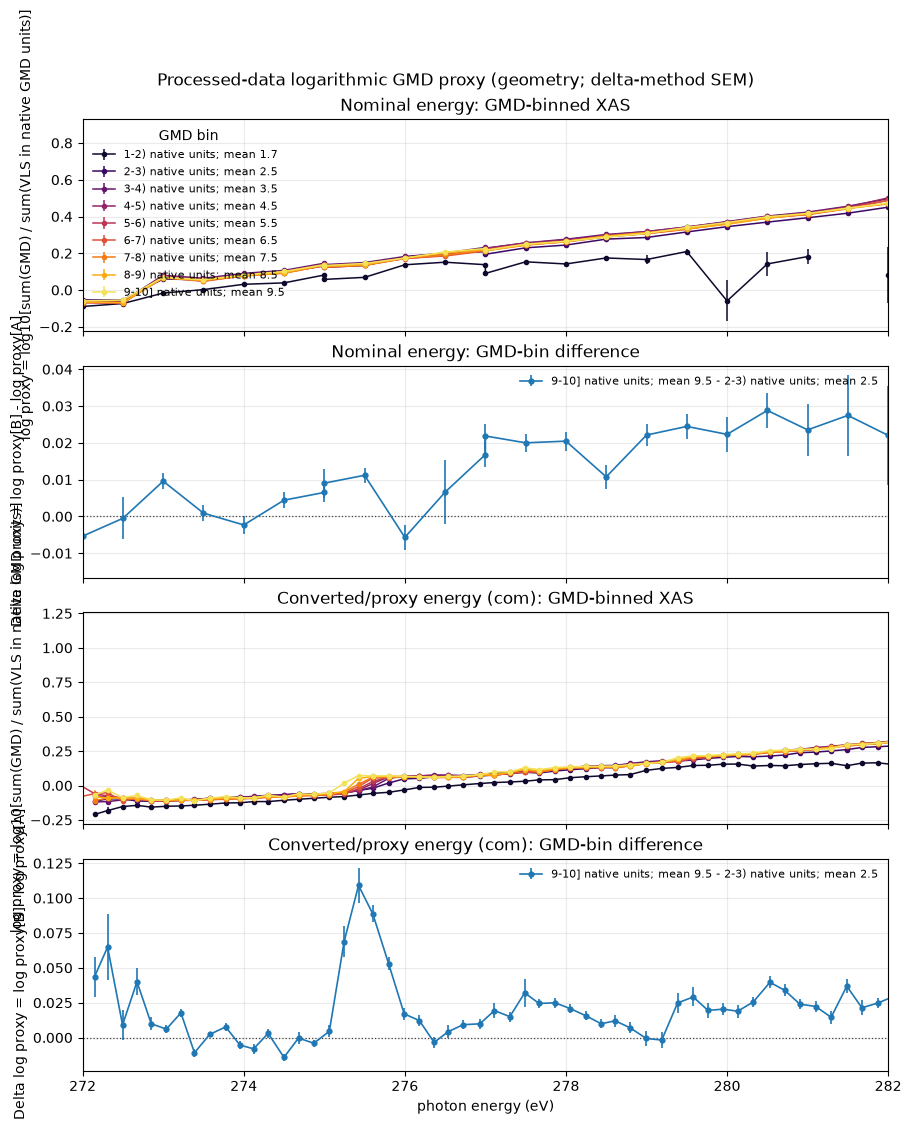

In [ ]:
if 'E' in HISTORICAL_SECTIONS:
    from historical import static_xas_thesis_core_xas as tx
    PROCESSED_PROXY_ENABLED = True
    PROCESSED_PROXY_CONFIG = tx.ThesisCoreXASConfig(
        input_h5=REVIEW_SAMPLE_H5, vls_intensity_threshold=1000.0,
        gmd_bin_mode='fixed', gmd_edges=tuple(np.arange(1.,11.,1.)), n_gmd_bins=5,
        gmd_min_threshold=None, gmd_max_threshold=10.0,
        center_method='com', center_half_window=5, center_chunk_size=50000,
        proxy_pixel_bin_width=1, correction_mode='per_energy_intercept',
        unit_scale_mode='reference_window', unit_reference_window_ev=(272.,273.), chunk_size=20000,
        pixel_map_config=dict(GMD_SIMPLE_PARAMS['PIXEL_MAP_CONFIG']),
        pixel_map_calibration=dict(GMD_SIMPLE_PARAMS['PIXEL_MAP_CALIBRATION']),
        inverse_map_range_ev=(260.,290.), inverse_map_samples=10000,
    )
    PROXY_DIFF_BIN_A = 1
    PROXY_DIFF_BIN_B = -1
    PROCESSED_PROXY_XLIM = (272.,282.)
    processed_proxy_result = None
    if PROCESSED_PROXY_ENABLED:
        schema=xc.processed_schema(PROCESSED_PROXY_CONFIG.input_h5)
        if 'ml/gmd_hall_channels' not in schema['datasets']: raise KeyError('Mapped hall GMD required')
        processed_proxy_result=tx.compute_thesis_core_xas(PROCESSED_PROXY_CONFIG)
        print('Selected populations:',processed_proxy_result.filter_counts)
        print('Empirical scale (legacy field vls_per_uJ, not calibrated µJ):',processed_proxy_result.unit_scale)
        fig, axes=tx.plot_xas_with_gmd_difference_matplotlib(processed_proxy_result,
            bin_a=PROXY_DIFF_BIN_A,bin_b=PROXY_DIFF_BIN_B,
            nominal_xlim=PROCESSED_PROXY_XLIM,converted_xlim=PROCESSED_PROXY_XLIM,show_errorbars=True)
        xc.relabel_native_gmd(fig,proxy=True)
        fig.suptitle('Processed-data logarithmic GMD proxy (geometry; delta-method SEM)')
        plt.show()
    else:
        print('Processed-data logarithmic proxy disabled.')


## F — Good-product logarithmic GMD proxy (empirical centre energy)

Source: updated `xas_static_good.ipynb` cells 1/2/4/6;
`static_xas_good_xas.py::read_good_shots/compute_good_xas/resolve_unit_scale`.
Requires an explicitly generated accepted-shot good product; current raw processed files
are not substitutes. The source notebook is configured for58780 despite saved sample-like
outputs; here58794 is an explicit sample choice. No product is assumed to exist.

This reader starts from **`/trans_raw`**, not the already corrected stored transmissions.
`per_axis_intercept` independently fits/removes intercepts in nominal-energy and centre-pixel
proxy groups. It then uses a single scale from **converted 271–272 eV**, unlike E's nominal
272–273 eV window. The converted x coordinate is the mean stored empirical shot energy
in each occupied centre-pixel bin. Thus E/F are alternatives, not equivalent replays.
`correction_mode='none'` retains raw intensity but still fits the explicitly configured scale.
Legacy fields named `_uJ`/`.od` are retained for source equivalence; displayed values are
empirically scaled detector signals and a logarithmic proxy, not absolute µJ or established OD.
No second subtraction of stored corrected transmissions is performed.


In [ ]:
if 'F' in HISTORICAL_SECTIONS:
    from historical import static_xas_good_xas as gx
    GOOD_PROXY_ENABLED = False
    GOOD_PROXY_INPUT = REVIEW_GOOD_DIR/'run58794_good_static_xas.h5'
    GOOD_PROXY_CONFIG = gx.GoodXASConfig(
        input_h5=GOOD_PROXY_INPUT, energy_window_ev=(271.,282.),
        unit_scale_axis='converted', unit_reference_window_ev=(271.,272.),
        gmd_edges=tuple(np.arange(1.,11.,1.)), gmd_min_threshold=None,gmd_max_threshold=10.,
        nominal_group_decimals=3,proxy_pixel_bin_width=1,
        correction_mode='per_axis_intercept',gmd_source='hall',
    )
    GOOD_PROXY_DIFF_BIN_A = 1
    GOOD_PROXY_DIFF_BIN_B = -1
    GOOD_PROXY_XLIM = (271.,282.)
    GOOD_PROXY_BOOTSTRAP_ENABLED = False
    GOOD_PROXY_N_BOOTSTRAP = 500
    GOOD_PROXY_BOOTSTRAP_SEED = 123
    GOOD_PROXY_BOOTSTRAP_MIN_SHOTS = 100
    GOOD_PROXY_BOOTSTRAP_BATCH = 50
    good_proxy_result = None
    good_proxy_bootstrap = None


In [ ]:
if 'F' in HISTORICAL_SECTIONS:
    if GOOD_PROXY_ENABLED:
        print(xc.good_schema(GOOD_PROXY_CONFIG.input_h5,gmd_source=GOOD_PROXY_CONFIG.gmd_source))
        good_proxy_result=gx.compute_good_xas(GOOD_PROXY_CONFIG)
        print('Accepted/downstream kept:',good_proxy_result.shots.gmd.size,int(good_proxy_result.keep_mask.sum()))
        print('Fitted empirical scale; vls_per_uJ is a legacy name:',good_proxy_result.unit_scale)
        print('Nominal/converted fit populations:',good_proxy_result.nominal_fits.n,good_proxy_result.converted_fits.n)
        print('Source section/row identities:',good_proxy_result.shots.section_index,good_proxy_result.shots.source_shot_index)
        if GOOD_PROXY_BOOTSTRAP_ENABLED:
            good_proxy_bootstrap=gx.compute_bootstrap_errors(good_proxy_result,
                n_bootstrap=GOOD_PROXY_N_BOOTSTRAP,seed=GOOD_PROXY_BOOTSTRAP_SEED,
                min_shots_per_bin=GOOD_PROXY_BOOTSTRAP_MIN_SHOTS,batch_size=GOOD_PROXY_BOOTSTRAP_BATCH)
        fig,axes=gx.plot_xas_with_gmd_difference_matplotlib(good_proxy_result,
            bootstrap=good_proxy_bootstrap,bin_a=GOOD_PROXY_DIFF_BIN_A,bin_b=GOOD_PROXY_DIFF_BIN_B,
            nominal_xlim=GOOD_PROXY_XLIM,converted_xlim=GOOD_PROXY_XLIM,show_errorbars=True)
        xc.relabel_native_gmd(fig,proxy=True)
        fig.suptitle('Good-product logarithmic GMD proxy; empirical scale, not absolute OD')
        plt.show()
    else:
        print('Good-product proxy disabled; required input:',GOOD_PROXY_INPUT,'exists:',GOOD_PROXY_INPUT.is_file())


Good-product proxy disabled; required input: /home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58794_good_static_xas.h5 exists: True


## G — Measured-reference alternative: sample58794 / reference58780

Source: updated `xas_static_good_reference.ipynb` cells 1–6;
`static_xas_good_reference.py::compute_reference_xas/read_reference_shots`.
Requires compatible good products for **both** runs. Reads already corrected
`/trans_intercept_corrected_nominal` and `/trans_intercept_corrected_converted`.
It does not refit/subtract intercepts or apply F's empirical detector/GMD scale.
The observable is `A=log10(mean(reference corrected VLS)/mean(sample corrected VLS))`.
GMD selects matching bins only; it is not divided out. This is a reference-based
absorbance estimator conditional on optical compatibility, background and response validity.

Nominal energies intersect rounded common labels. Converted spectra use each run's own
empirical shot energies, then **linear interpolation of reference means, SEMs, counts and
mean GMD onto the sample grid, separately per GMD bin**, with no extrapolation. Interpolated
reference counts can be fractional and are not measured exposures. SEM interpolation and
shared references need scientific review. Stored source grids remain accessible.
Unlike B, this averages corrected integrated shot intensities rather than clipping mean
spectra at zero before integrating. Therefore any difference is not attributable to GMD alone.
The baseline/feature windows below only diagnose slopes; they do not subtract a baseline.


In [ ]:
if 'G' in HISTORICAL_SECTIONS:
    from historical import static_xas_good_reference as gr
    GOOD_REFERENCE_ENABLED = False
    GOOD_REFERENCE_SAMPLE = REVIEW_GOOD_DIR/'run58794_good_static_xas.h5'
    GOOD_REFERENCE_REFERENCE = REVIEW_GOOD_DIR/'run58780_good_static_xas.h5'
    GOOD_REFERENCE_CONFIG = gr.ReferenceXASConfig(
        sample_h5=GOOD_REFERENCE_SAMPLE,reference_h5=GOOD_REFERENCE_REFERENCE,
        gmd_edges=tuple(np.arange(1.,11.,1.)),gmd_min_threshold=None,gmd_max_threshold=10.,
        nominal_group_decimals=3,proxy_pixel_bin_width=1,
        baseline_window_ev=(271.,280.),exclude_feature_windows_ev=((272.8,273.2),(274.8,275.2)),
        gmd_source='hall',
    )
    GOOD_REFERENCE_DIFF_BIN_A = 1
    GOOD_REFERENCE_DIFF_BIN_B = -1
    GOOD_REFERENCE_XLIM = (271.,282.)
    good_reference_result = None


In [ ]:
if 'G' in HISTORICAL_SECTIONS:
    if GOOD_REFERENCE_ENABLED:
        good_input_metadata=[xc.good_schema(p,reference=True,gmd_source=GOOD_REFERENCE_CONFIG.gmd_source)
                             for p in (GOOD_REFERENCE_CONFIG.sample_h5,GOOD_REFERENCE_CONFIG.reference_h5)]
        for meta in good_input_metadata: print(meta)
        good_reference_result=gr.compute_reference_xas(GOOD_REFERENCE_CONFIG)
        print('Sample/reference accepted then selected:',good_reference_result.sample_shots.n_shots,
            good_reference_result.reference_shots.n_shots,int(good_reference_result.sample_keep.sum()),int(good_reference_result.reference_keep.sum()))
        good_reference_nominal_counts=gr.counts_table(good_reference_result,axis='nominal')
        good_reference_converted_counts=gr.counts_table(good_reference_result,axis='converted')
        print(good_reference_nominal_counts.head(20).to_string(index=False))
        print(good_reference_converted_counts.head(20).to_string(index=False))
        for axis in ('nominal','converted'):
            grid=getattr(good_reference_result,axis)
            print(axis,'invalid absorbance cells:',int((~np.isfinite(grid.absorbance)).sum()),
                  'sample counts:',grid.sample_counts,'reference counts (converted interpolated):',grid.reference_counts)
        fig,axes=gr.plot_reference_xas_matplotlib(good_reference_result,
            bin_a=GOOD_REFERENCE_DIFF_BIN_A,bin_b=GOOD_REFERENCE_DIFF_BIN_B,
            nominal_xlim=GOOD_REFERENCE_XLIM,converted_xlim=GOOD_REFERENCE_XLIM,show_errorbars=True)
        xc.relabel_native_gmd(fig)
        plt.show()
    else:
        print('Measured-reference good workflow disabled; required products:',GOOD_REFERENCE_SAMPLE,GOOD_REFERENCE_REFERENCE)


Measured-reference good workflow disabled; required products: /home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58794_good_static_xas.h5 /home/mmanresa/FLASH_Gotthard/products/static_xas_good/run58780_good_static_xas.h5


## Task B: controlled comparison order and limits

1. Run C metadata/populations first; independently inspect stored train/pulse identities against notebook01.
   Quantify root/mapped finite/selected masks, spectra, T/G diagnostics and changed rows without shifting any data.
2. Run C simple then historical-reference replay separately, keeping parameters fixed. Root must reproduce the
   Stage1D arrays first. Compare mapped-root values/counts on exact common coordinates; report unmatched bins,
   changed validity and populations. Matching root/mapped sample results are an important control.
3. Run bounded D on58794 and58780; inspect SNR versus historical peak selection. It is a preview, not full-run
   acceptance or calibration. Notebook02 owns empirical versus geometry validation.
4. Run E with existing processed inputs, then compare correction/scaling choices one at a time. Retain fitted
   intercepts, populations, raw/corrected integrals and empirical scale; no method is selected as superior.
5. F/G require separately authorized good-product generation in the project, with exact source/config/input
   provenance and calibration validation. Compare raw versus once-corrected quantities and inspect preserved
   source-shot indices. For G check common energies, per-bin GMD means/counts, invalid/nonpositive ratios and
   interpolation coverage against native grids. Physical reference compatibility remains a separate question.

New methods have **not been executed**. Bootstrap is opt-in (source500 replicates); otherwise plots use the
source delta-method SEM. Shot-level SEM/bootstrap does not account for train correlation or calibration/fit
uncertainty; interpolated reference errors are not an independent uncertainty validation.
The 282/284eV section4 history and old reference58870/58871 calculations remain untouched.
There is no automatic new filtering, alignment, background correction, energy relabelling, smoothing,
absolute GMD calibration or output saving. Repeated geometrical calibration and generic detector plots,
Plotly duplicates and repeated proxy/bootstrap notebooks are deliberately not added.
